# WTI forecasting with SVR

Standalone adaptation of the matching `BTC_TEST` notebook and the `time-series-forecasting` skill. Source: `CSV/WTI_USD Historical Data.csv`; target: `Price`; units: **USD (source price)**.

**Flow:** source audit → raw chronological 80/20 Train/Test (no validation) → descriptive EDA → Train-only development and diagnostics → frozen rolling-origin Test forecasts → separate latest-origin future forecasts → RMSE/MAPE by horizon → plots and execution-generated summary.

**Asset adaptation declared before Test:** horizons [1, 5, 10, 20] count successive **observations**, not calendar days or a guaranteed month. Window models use 40 observed returns (roughly eight 5-day weeks, or fewer weeks for the WTI source). No artificial weekend/holiday prices. The supplied CSV has no exchange-calendar metadata; missing dates are disclosed. Future dates are projected from a declared weekday pattern and are not confirmed exchange sessions.

Run all cells from a fresh **Python 3.12 (vs_nine TensorFlow)** kernel using `C:/Users/User/anaconda3/envs/vs_nine_tf/python.exe`. Versions and actual executable are printed and saved. Output: `OUTPUT/SVR_WTI/{tables,figures,summaries,models}`.

The CSV identifies WTI/USD but does not identify instrument, contract, roll/adjustment treatment, close time, or timezone. Do not claim a specific futures contract or roll convention. Physical quotation is conventionally USD/barrel, but the file contains no unit metadata; metrics retain source USD price units.

**Horizon update:** `[1, 3, 5, 7, 14, 21, 30]` observed steps, as explicitly requested by the user. Previous cell outputs were cleared. Restart the kernel and run all cells to regenerate models, forecasts, metrics and exported results for this configuration; existing files in OUTPUT still belong to the previous execution until rerun.


### SVR results navigation — current Train-only search experiment

- [Top 5 parameter sets per horizon](#svr-top5-train): **section 7.1**, before final fitting and Test.
- [Original archived future evaluation](#task1-future-metrics): retained original forecasts.
- [Revised future evaluation](#svr-revised-future): new Train-ranked forecasts, retrospective.
- [Task 2 — current Test RMSE/MAPE](#task2-test-metrics): selected rank-1 models, fixed during inference.

The candidate grid is declared in the main configuration cell. Search outputs: `OUTPUT/SVR_TRAIN_SEARCH/WTI/tables/`. No Test or future metric is used to select candidates.


## 1. Imports and environment

In [1]:
from pathlib import Path
import os, sys, json, random, hashlib, warnings, time
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import joblib
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from IPython.display import display, Markdown, HTML

from sklearn.svm import SVR
from sklearn.neighbors import NearestNeighbors
from sklearn.exceptions import ConvergenceWarning

## 2. Single configuration cell
All experiment settings are declared before Test inference. These are reference-informed fixed settings, not claimed asset-specific optima. Change them only as a new, explicitly documented experiment after viewing Test.

In [2]:
ASSET = 'WTI'
ASSET_NAME = 'WTI'
MODEL = 'SVR'
UNIT = 'USD (source price)'
ASSET_NOTE = 'The CSV identifies WTI/USD but does not identify instrument, contract, roll/adjustment treatment, close time, or timezone. Do not claim a specific futures contract or roll convention. Physical quotation is conventionally USD/barrel, but the file contains no unit metadata; metrics retain source USD price units.'
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CSV' / 'WTI_USD Historical Data.csv').is_file()), None)
if PROJECT_ROOT is None: raise FileNotFoundError('Start Jupyter in PROJECT_2026 or the asset notebook folder.')
DATA_PATH = PROJECT_ROOT / 'CSV' / 'WTI_USD Historical Data.csv'
DATE_COL, TARGET_COL, DATE_FORMAT = 'Date', 'Price', '%m/%d/%Y'
TRAIN_RATIO = 0.8
HORIZONS = [1, 3, 5, 7, 14, 21, 30]
DAILY_FORECAST_WINDOWS = [7, 30]
LOOKBACK = 40
TRANSFORMATION = 'log price for ARIMA; observed-step log returns for feature/MIMO models'
WEEKMASK = 'Mon Tue Wed Thu Fri Sun'
CALENDAR_NOTE = 'Observation-index modeling; source dates retained without filling gaps. Future dates use the declared weekday pattern only; holidays, omitted records and source-session conventions remain unknown.'
CALENDAR_POLICY_USER_ACKNOWLEDGED = False
SEEDS = [0]
ALPHA = 0.05
DIAGNOSTIC_LAGS = [10,20,30]
ROLLING_WINDOW = 20
SETTINGS = {'kernel': 'rbf', 'gamma': 'scale', 'knn_k': 3, 'rule': 'Train price RMSE ranking around analytical C/epsilon/gamma references'}

# Fixed candidate design, declared before any Test/future scoring.
SVR_SEARCH_CONFIG = dict(C_multipliers=[0.5, 1.0, 2.0],
    epsilon_multipliers=[0.5, 1.0, 2.0], gamma_multipliers=[0.5, 1.0, 2.0],
    top_n=5, ranking='Train RMSE in original price units',
    validation=False, cross_validation=False, run_id='svr_train_rmse_top5_v1')

PACKAGES = ['numpy', 'pandas', 'matplotlib', 'scipy', 'statsmodels', 'scikit-learn', 'joblib']
assert max(DAILY_FORECAST_WINDOWS) <= max(HORIZONS)

## 3. Output helpers, provenance and diagnostics
Process checks enforce chronology, leakage prevention and frozen fitted state. Statistical diagnostics with no declared selection threshold are marked **REPORTED**. No statistical test on Test controls tuning or refitting.

In [3]:
assert HORIZONS == sorted(set(HORIZONS)) and min(HORIZONS) >= 1
MAX_H = max(HORIZONS)
OUTPUT_DIR = PROJECT_ROOT / 'OUTPUT' / f'{MODEL}_{ASSET}'
TABLE_DIR, FIGURE_DIR, SUMMARY_DIR, MODEL_DIR = [OUTPUT_DIR / k for k in ['tables','figures','summaries','models']]
for directory in [TABLE_DIR, FIGURE_DIR, SUMMARY_DIR, MODEL_DIR]: directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (12, 4.5), 'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .2})
def save_table(frame, name): frame.to_csv(TABLE_DIR / name, index=False, encoding='utf-8-sig')
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / name, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)
def show_table(frame):
    display(HTML('<div style="max-height:340px;overflow:auto;border:1px solid #ddd">' +
                 frame.to_html(index=False, float_format=lambda x: f'{x:,.6f}') + '</div>'))
def write_json(path, obj): path.write_text(json.dumps(obj, indent=2, default=str, ensure_ascii=False), encoding='utf-8')
def markdown_table(frame):
    def cell(x):
        if isinstance(x,(float,np.floating)): return f'{x:.6f}'
        return str(x).replace('|','/').replace('\n',' ')
    return '\n'.join(['| '+' | '.join(map(str,frame.columns))+' |',
        '| '+' | '.join(['---']*len(frame.columns))+' |']+
        ['| '+' | '.join(cell(x) for x in row)+' |' for row in frame.itertuples(index=False,name=None)])
def warning_text(caught): return ' | '.join(f'{w.category.__name__}: {w.message}' for w in caught)
versions = pd.DataFrame([(p, version(p)) for p in PACKAGES], columns=['library','version'])
save_table(versions, 'library_versions.csv')
display(versions)
print('Python:', sys.version, '\nExecutable:', sys.executable, '\nData:', DATA_PATH, '\nOutput:', OUTPUT_DIR)
configuration = dict(asset=ASSET, model=MODEL, data=str(DATA_PATH), target=TARGET_COL, date_column=DATE_COL,
    date_format=DATE_FORMAT, unit=UNIT, asset_note=ASSET_NOTE, train_ratio=TRAIN_RATIO,
    horizons=HORIZONS, daily_forecast_windows=DAILY_FORECAST_WINDOWS, horizon_unit='observations', calendar=CALENDAR_NOTE, weekmask=WEEKMASK,
    lookback=LOOKBACK, transformation=TRANSFORMATION, seeds=SEEDS, settings=SETTINGS,
    alpha=ALPHA, validation=False, evaluation='rolling origins from final Train row; frozen fitted parameters',
    design_source='BTC_TEST implementation reference + time-series-forecasting skill; asset-specific adaptation declared before Test',
    python_executable=sys.executable, python_version=sys.version)
write_json(SUMMARY_DIR / 'configuration.json', configuration)
process_rows = []
def check(name, condition, note='', statistic=None):
    process_rows.append(dict(check=name, statistic=statistic, p_value=np.nan,
                             status='PASS' if bool(condition) else 'FAIL', interpretation=note))
    save_table(pd.DataFrame(process_rows), 'process_checks.csv')
    assert condition, f'{name}: {note}'
def residual_report(values, label, model_df=0):
    values = np.asarray(values, dtype=float)
    assert np.isfinite(values).all()
    rows = []
    lags = [lag for lag in DIAGNOSTIC_LAGS if model_df < lag < len(values)//2]
    lb = acorr_ljungbox(values, lags=lags, model_df=model_df, return_df=True)
    for lag, row in lb.iterrows():
        rows.append(dict(sample=label, check=f'Ljung-Box lag {lag}', statistic=row.lb_stat,
            p_value=row.lb_pvalue, status='REPORTED', interpretation=('Evidence of serial correlation' if row.lb_pvalue <= ALPHA else 'No rejection of residual independence') + f'; model_df={model_df}; reporting only'))
    t, p = stats.ttest_1samp(values, 0.)
    rows.append(dict(sample=label, check='Residual mean t-test', statistic=t, p_value=p, status='REPORTED',
        interpretation=f'Mean={values.mean():.8g}; descriptive, dependent errors limit the t-test'))
    lm, p, _, _ = het_arch(values, nlags=min(10, len(values)//5), ddof=model_df)
    rows.append(dict(sample=label, check='ARCH LM', statistic=lm, p_value=p, status='REPORTED',
        interpretation='Conditional variance evidence; no retuning'))
    jb, p, skew, kurt = jarque_bera(values)
    rows.append(dict(sample=label, check='Jarque-Bera', statistic=jb, p_value=p, status='REPORTED',
        interpretation=f'Normality diagnostic; skew={skew:.5g}; kurtosis={kurt:.5g}; no retuning'))
    return pd.DataFrame(rows)

,library,version
0,numpy,2.5.3
1,pandas,2.3.3
2,matplotlib,3.11.1
3,scipy,1.18.1
4,statsmodels,0.15.0
5,scikit-learn,1.9.1
6,joblib,1.6.0


Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)] 
Executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe 
Data: C:\Users\User\Desktop\PROJECT_2026\CSV\WTI_USD Historical Data.csv 
Output: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\SVR_WTI


## 4. Source audit and preparation
Parse US-style dates and comma-separated prices. Stop on invalid or duplicate targets. Do not resample or silently fill/drop source observations. Auxiliary OHLC/volume columns are not features. The date-gap audit distinguishes observed records from unverified holidays or omissions.

In [4]:
raw = pd.read_csv(DATA_PATH, dtype=str, encoding='utf-8-sig')
assert {DATE_COL,TARGET_COL}.issubset(raw.columns)
dates = pd.to_datetime(raw[DATE_COL], format=DATE_FORMAT, errors='coerce')
price = pd.to_numeric(raw[TARGET_COL].str.replace(',', '', regex=False).str.strip(), errors='coerce')
invalid = dates.isna() | ~np.isfinite(price) | price.le(0)
duplicates = dates.duplicated(keep=False)
save_table(raw.loc[invalid | duplicates], 'invalid_or_duplicate_source_rows.csv')
check('Valid dates, finite strictly positive targets, unique dates', not (invalid | duplicates).any(),
      'Log representation was predetermined; stop rather than impute, drop, or offset invalid targets.')
df = pd.DataFrame({'Date': dates, 'Price': price}).sort_values('Date').set_index('Date')
n = len(df)
n_train = int(TRAIN_RATIO * n)
n_test = n - n_train
T = n_train - 1
prices = df.Price.to_numpy()
log_price = np.log(prices)
returns = np.r_[np.nan, np.diff(log_price)]
check('Chronological raw 80/20 partition', df.index.is_monotonic_increasing and df.index.is_unique and n_train == int(.8*n),
      'No shuffling, validation partition, or target imputation.')
check('Sufficient Train/Test history', n_train > LOOKBACK + MAX_H + 10 and n_test >= MAX_H,
      'Requested horizons and lookback must remain feasible without shortening.')
source_order = 'descending' if dates.is_monotonic_decreasing else ('ascending' if dates.is_monotonic_increasing else 'mixed')
calendar_offset = pd.offsets.CustomBusinessDay(weekmask=WEEKMASK)
expected_calendar = pd.date_range(df.index[0], df.index[-1], freq=calendar_offset)
missing_dates = expected_calendar.difference(df.index)
unexpected_dates = df.index.difference(expected_calendar)
save_table(pd.DataFrame({'date': missing_dates, 'classification': 'not observed; holiday/omission unknown; no imputation'}), 'calendar_missing_dates.csv')
save_table(pd.DataFrame({'date': unexpected_dates}), 'calendar_unexpected_dates.csv')
gaps = pd.DataFrame({'previous_date': df.index[:-1], 'next_date': df.index[1:],
                     'calendar_days': np.diff(df.index.values).astype('timedelta64[D]').astype(int)})
save_table(gaps, 'observation_gaps.csv')
quality = pd.DataFrame([dict(rows=n, source_order=source_order, invalid_targets=int(invalid.sum()),
    duplicate_dates=int(duplicates.sum()), nonpositive_targets=int(price.le(0).sum()),
    missing_relative_to_weekmask=len(missing_dates), unexpected_weekdays=len(unexpected_dates),
    maximum_calendar_gap=int(gaps.calendar_days.max()), volume_missing=int(raw['Vol.'].isna().sum()) if 'Vol.' in raw else None,
    first_date=df.index[0], last_date=df.index[-1], source_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    gap_policy=CALENDAR_NOTE)])
save_table(quality, 'data_quality.csv')
save_table(df.reset_index(), 'prepared_target.csv')
display(quality.T)
show_table(gaps.loc[gaps.calendar_days.gt(3)])
show_table(pd.DataFrame({'unobserved_date': missing_dates}))
print(ASSET_NOTE)
print(CALENDAR_NOTE)
print('Only Date and Price are model inputs; blank auxiliary volume is retained in source and is not imputed.')

,0
rows,1601
source_order,descending
invalid_targets,0
duplicate_dates,0
nonpositive_targets,0
missing_relative_to_weekmask,25
unexpected_weekdays,0
maximum_calendar_gap,10
volume_missing,1601
first_date,2021-07-01 00:00:00


previous_date,next_date,calendar_days
2024-08-16,2024-08-26,10
2025-10-23,2025-10-27,4


unobserved_date
2021-07-25
2021-12-24
2022-04-15
2022-12-25
2023-01-01
2023-03-19
2023-04-07
2023-12-24
2023-12-31
2024-02-18


The CSV identifies WTI/USD but does not identify instrument, contract, roll/adjustment treatment, close time, or timezone. Do not claim a specific futures contract or roll convention. Physical quotation is conventionally USD/barrel, but the file contains no unit metadata; metrics retain source USD price units.
Observation-index modeling; source dates retained without filling gaps. Future dates use the declared weekday pattern only; holidays, omitted records and source-session conventions remain unknown.
Only Date and Price are model inputs; blank auxiliary volume is retained in source and is not imputed.


## 5. Raw chronological Train/Test split
Split before learned scaling and windows; exact counts and dates are derived from this file. No validation subset.

,partition,rows,start_date,end_date
0,Train,1280,2021-07-01,2025-08-27
1,Test,321,2025-08-28,2026-09-09


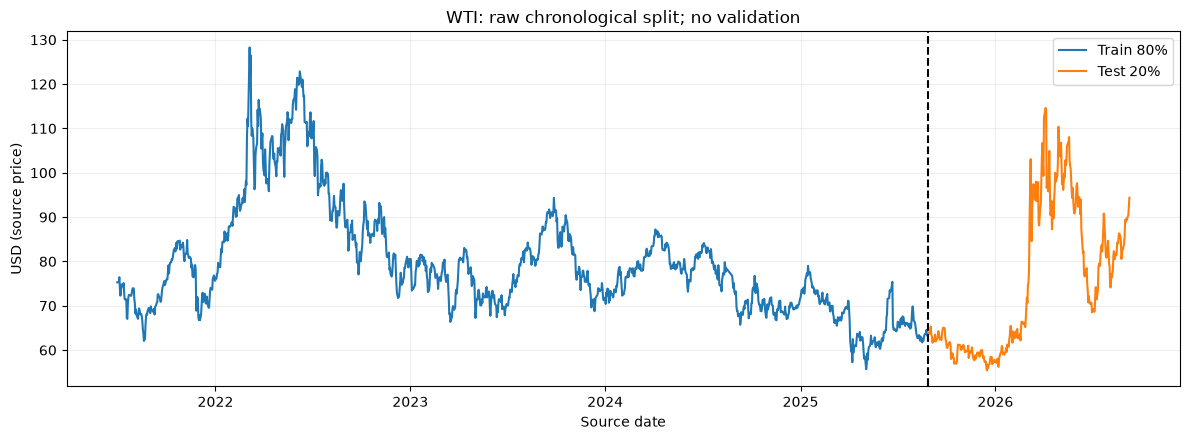

In [5]:
split_summary = pd.DataFrame([dict(partition=label, rows=b-a, start_date=df.index[a], end_date=df.index[b-1])
                             for label,a,b in [('Train',0,n_train),('Test',n_train,n)]])
save_table(split_summary, 'split_summary.csv')
display(split_summary)
fig, ax = plt.subplots()
ax.plot(df.index[:n_train], prices[:n_train], label='Train 80%')
ax.plot(df.index[n_train:], prices[n_train:], label='Test 20%')
ax.axvline(df.index[n_train], color='black', linestyle='--')
ax.set(title=f'{ASSET_NAME}: raw chronological split; no validation', ylabel=UNIT, xlabel='Source date')
ax.legend(); save_figure(fig, '01_raw_split.png')

## 6. Descriptive EDA
These full-sample plots describe the supplied data; model settings remain the previously declared ones.

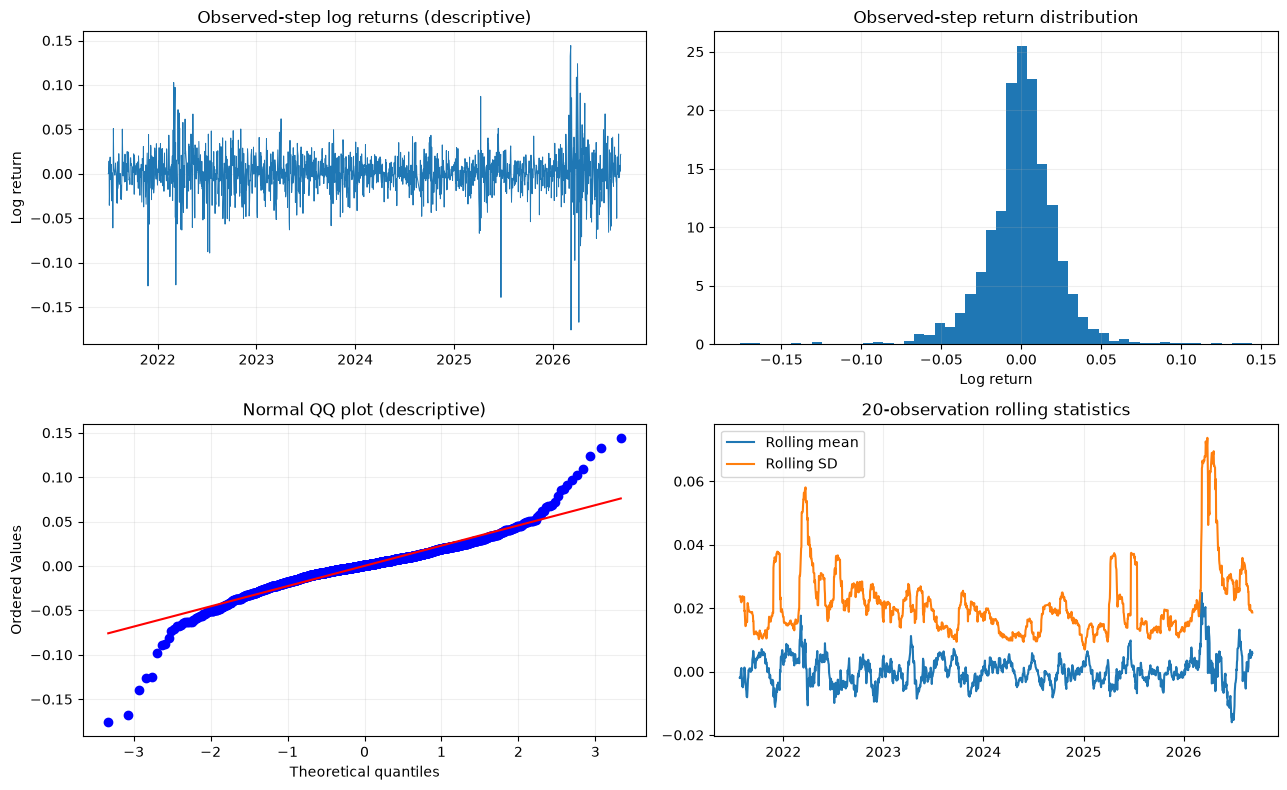

In [6]:
# Full-sample descriptive plots do not supply model settings or selection decisions.
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0,0].plot(df.index[1:], returns[1:], linewidth=.7)
axes[0,0].set(title='Observed-step log returns (descriptive)', ylabel='Log return')
axes[0,1].hist(returns[1:], bins=50, density=True)
axes[0,1].set(title='Observed-step return distribution', xlabel='Log return')
stats.probplot(returns[1:], dist='norm', plot=axes[1,0])
axes[1,0].set_title('Normal QQ plot (descriptive)')
rolling = pd.Series(returns, index=df.index).rolling(ROLLING_WINDOW)
axes[1,1].plot(rolling.mean(), label='Rolling mean')
axes[1,1].plot(rolling.std(), label='Rolling SD')
axes[1,1].set_title(f'{ROLLING_WINDOW}-observation rolling statistics')
axes[1,1].legend(); save_figure(fig, '02_descriptive_eda.png')

### Descriptive Statistics

Price and observed-step log return, reported separately for the full sample,
the first 80% (Train), and the final 20% (Test), using the notebook's raw
chronological split before scaling or windowing. Columns identify each sample;
rows give units, dates, Count, Mean, SD, Min, Q1, Median, Q3, Max, Skewness,
and Excess kurtosis.

SD uses `ddof=1`; skewness and excess kurtosis use pandas' bias-corrected
estimators (normal-distribution excess kurtosis = 0). Log returns are natural-log
changes, not percentages, across successive observed dates. The first full-sample
return is undefined and excluded. Returns belong to their ending date, so the
first Test return uses the last Train price. Calendar gaps are not filled.
Full-sample and Test statistics are descriptive reporting only, not inputs to
model selection or fitting. The tables below were calculated from the supplied
source data without rerunning model training.


In [7]:
# Descriptive reporting only; this cell does not fit or configure a model.
def _make_descriptive_statistics(price, train_ratio):
    assert price.index.is_monotonic_increasing and price.index.is_unique
    assert price.notna().all() and np.isfinite(price).all() and price.gt(0).all()
    split = int(train_ratio * len(price))
    assert 0 < split < len(price)
    # Assign returns to their ending date; retain the Train-to-Test boundary return.
    log_return = np.log(price).diff()
    rows = []
    for variable, series, unit in [('Price', price, 'USD (source price)'),
                                    ('Log return', log_return, 'natural log; not percent')]:
        for sample, start, end in [('Full sample', 0, len(price)),
                                    ('Train', 0, split), ('Test', split, len(price))]:
            values = series.iloc[start:end].dropna()
            summary = values.describe(percentiles=[0.25, 0.5, 0.75])
            rows.append({'Variable': variable, 'Sample': sample, 'Unit': unit,
                'Start': str(values.index[0].date()), 'End': str(values.index[-1].date()),
                'Count': int(summary['count']), 'Mean': summary['mean'],
                'SD': summary['std'], 'Min': summary['min'], 'Q1': summary['25%'],
                'Median': summary['50%'], 'Q3': summary['75%'], 'Max': summary['max'],
                'Skewness': values.skew(), 'Excess kurtosis': values.kurt()})
    return pd.DataFrame(rows)

descriptive_statistics = _make_descriptive_statistics(df['Price'], TRAIN_RATIO)
del _make_descriptive_statistics
for _descriptive_variable in ['Price', 'Log return']:
    print(_descriptive_variable)
    display(descriptive_statistics.loc[
        descriptive_statistics['Variable'].eq(_descriptive_variable)
    ].drop(columns='Variable').set_index('Sample').T)
del _descriptive_variable

Price


Sample,Full sample,Train,Test
Unit,USD (source price),USD (source price),USD (source price)
Start,2021-07-01,2021-07-01,2025-08-28
End,2026-09-09,2025-08-27,2026-09-09
Count,1601,1280,321
Mean,78.479038,79.316008,75.141589
SD,13.413534,12.482122,16.214575
Min,55.43,55.69,55.43
Q1,69.34,70.8325,60.54
Median,76.61,77.085,69.26
Q3,84.67,84.1025,89.74


Log return


Sample,Full sample,Train,Test
Unit,natural log; not percent,natural log; not percent,natural log; not percent
Start,2021-07-02,2021-07-02,2025-08-28
End,2026-09-09,2025-08-27,2026-09-09
Count,1600,1279,321
Mean,0.000141,-0.000132,0.00123
SD,0.023796,0.021209,0.032118
Min,-0.175977,-0.139251,-0.175977
Q1,-0.010166,-0.009932,-0.010752
Median,0.000871,0.000624,0.001594
Q3,0.01184,0.011387,0.014347


## 7. Train-only input scaling
One scaler is fitted on raw Train observed-step log returns, excluding the initial undefined return. Each direct target scaler is fitted on its own Train targets.

In [8]:
scaler = StandardScaler().fit(returns[1:n_train, None])
check('Scaler fitted on Train only', int(scaler.n_samples_seen_) == n_train - 1,
      f'Fit dates {df.index[1].date()} through {df.index[T].date()}; first undefined return excluded.')
np.testing.assert_allclose(scaler.mean_[0], returns[1:n_train].mean(), atol=1e-12)
np.testing.assert_allclose(scaler.scale_[0], returns[1:n_train].std(ddof=0), atol=1e-12)
z = np.full(n, np.nan)
z[1:] = scaler.transform(returns[1:,None]).ravel()
scaler_hash = joblib.hash(scaler)
joblib.dump(scaler, MODEL_DIR / 'input_scaler.joblib')
write_json(MODEL_DIR / 'scaler_provenance.json', dict(first_index=1, last_index=T,
    first_date=df.index[1], last_date=df.index[T], n_samples=n_train-1,
    mean=float(scaler.mean_[0]), scale=float(scaler.scale_[0]), ddof=0, sha256=scaler_hash))

<a id="svr-top5-train"></a>

### 7.1 — SVR Top 5 parameter sets per horizon (Train RMSE only)

The user-requested experiment keeps the chronological Train/Test 80/20 split and no validation or cross-validation. Test and supplied future actuals never enter candidate fitting, ranking, tie-breaking or selection. Each horizon uses 27 fixed combinations: C, epsilon and gamma multipliers 0.5/1/2 around its original Train-derived analytical settings. Kernel and lookback remain unchanged. All 30 daily-path horizons follow the same search rule.

Show **five distinct parameter sets for each of h=1,3,5,7,14,21,30**, ranked by Train RMSE in original price units; ties use candidate ID. Train MAPE is descriptive only. Rank 1 is fixed before Test. A low in-sample RMSE does not establish the best model for new observations. The existing Test and future-actual periods have already been inspected: this rerun is a retrospective experiment, not a new untouched holdout.


Epsilon is measured on standardized cumulative log-return targets; it is not a price or a price percentage. Only Train RMSE is expressed in original price units.


In [9]:
# All candidate fitting/ranking uses only the original Train 80%.
from itertools import product
svr_search_root = next(base for base in [Path.cwd(), *Path.cwd().parents]
    if (base / 'CSV').is_dir() and (base / 'ACTUAL_FOR_PREDICT').is_dir())
svr_search_output = svr_search_root / 'OUTPUT' / 'SVR_TRAIN_SEARCH' / 'WTI'
svr_search_table_dir = svr_search_output / 'tables'
svr_search_summary_dir = svr_search_output / 'summaries'
for svr_directory in [svr_search_table_dir, svr_search_summary_dir]:
    svr_directory.mkdir(parents=True, exist_ok=True)
svr_search_train_end = n_train - 1
svr_search_k = SETTINGS['knn_k']
svr_search_kernel = SETTINGS['kernel']
assert svr_search_kernel == 'rbf'
svr_search_rows = []
svr_search_log_price = np.asarray(log_price, dtype=float)
svr_search_prices = df['Price'].to_numpy(dtype=float)
svr_search_origins = {}
for svr_h in range(1, max(HORIZONS) + 1):
    svr_origins = np.arange(LOOKBACK, n_train-svr_h)
    svr_indices = svr_origins[:, None]-np.arange(LOOKBACK-1, -1, -1)[None, :]
    svr_targets = svr_origins+svr_h
    assert svr_targets.max() == svr_search_train_end
    assert svr_indices.min() >= 1 and (svr_indices <= svr_origins[:, None]).all()
    assert len(svr_origins) == n_train-LOOKBACK-svr_h
    svr_search_origins[svr_h] = svr_origins.copy()
    svr_X = z[svr_indices]
    svr_y = svr_search_log_price[svr_targets]-svr_search_log_price[svr_origins]
    svr_y_scaler = StandardScaler().fit(svr_y[:, None])
    svr_ys = svr_y_scaler.transform(svr_y[:, None]).ravel()
    assert np.isfinite(svr_X).all() and np.isfinite(svr_ys).all()
    svr_base_C = max(abs(svr_ys.mean()+3*svr_ys.std(ddof=0)), abs(svr_ys.mean()-3*svr_ys.std(ddof=0)))
    svr_neighbors = NearestNeighbors(n_neighbors=svr_search_k+1).fit(svr_X).kneighbors(svr_X, return_distance=False)
    svr_others = np.stack([indices[indices != i][:svr_search_k] for i, indices in enumerate(svr_neighbors)])
    assert (svr_others != np.arange(len(svr_y))[:, None]).all()
    svr_knn_mse = np.mean((svr_ys-svr_ys[svr_others].mean(axis=1))**2)
    svr_a = len(svr_y)**0.2*svr_search_k
    svr_sigma = float(np.sqrt(svr_a/(svr_a-1)*svr_knn_mse))
    svr_base_epsilon = float(3*svr_sigma*np.sqrt(np.log(len(svr_y))/len(svr_y)))
    svr_base_gamma = float(1/(svr_X.shape[1]*svr_X.var()))
    svr_grid = list(product(SVR_SEARCH_CONFIG['C_multipliers'],
        SVR_SEARCH_CONFIG['epsilon_multipliers'], SVR_SEARCH_CONFIG['gamma_multipliers']))
    assert len(svr_grid) == 27
    for svr_id, (svr_cm, svr_em, svr_gm) in enumerate(svr_grid, start=1):
        svr_C, svr_epsilon, svr_gamma = svr_base_C*svr_cm, svr_base_epsilon*svr_em, svr_base_gamma*svr_gm
        svr_candidate = SVR(kernel=svr_search_kernel, C=svr_C, epsilon=svr_epsilon, gamma=svr_gamma)
        svr_row = dict(asset='WTI', h=svr_h, candidate_id=svr_id, kernel=svr_search_kernel,
            lookback=LOOKBACK, C=svr_C, epsilon=svr_epsilon, gamma=svr_gamma,
            C_multiplier=svr_cm, epsilon_multiplier=svr_em, gamma_multiplier=svr_gm,
            base_C=svr_base_C, base_epsilon=svr_base_epsilon, base_gamma=svr_base_gamma,
            sigma_hat=svr_sigma, n_train=len(svr_y),
            first_train_target_date=df.index[svr_targets.min()], last_train_target_date=df.index[svr_targets.max()],
            Train_RMSE=np.nan, Train_MAPE_percent=np.nan, train_RMSE_scaled=np.nan,
            fit_status=-1, convergence_warning=False, eligible=False, warnings='')
        try:
            with warnings.catch_warnings(record=True) as svr_caught:
                warnings.simplefilter('always')
                svr_candidate.fit(svr_X, svr_ys)
            svr_pred_scaled = svr_candidate.predict(svr_X)
            svr_pred_return = svr_y_scaler.inverse_transform(svr_pred_scaled[:, None]).ravel()
            svr_pred_price = svr_search_prices[svr_origins]*np.exp(svr_pred_return)
            svr_actual_price = svr_search_prices[svr_targets]
            svr_convergence_warning = any(issubclass(w.category, ConvergenceWarning) for w in svr_caught)
            svr_eligible = (svr_candidate.fit_status_ == 0 and not svr_convergence_warning
                and np.isfinite(svr_pred_price).all() and (svr_pred_price > 0).all())
            svr_row.update(fit_status=int(svr_candidate.fit_status_), convergence_warning=svr_convergence_warning,
                eligible=bool(svr_eligible), support_vectors=int(svr_candidate.n_support_.sum()),
                warnings=' | '.join(str(w.message) for w in svr_caught))
            if svr_eligible:
                svr_row.update(Train_RMSE=float(np.sqrt(np.mean((svr_actual_price-svr_pred_price)**2))),
                    Train_MAPE_percent=float(100*np.mean(np.abs((svr_actual_price-svr_pred_price)/svr_actual_price))),
                    train_RMSE_scaled=float(np.sqrt(np.mean((svr_ys-svr_pred_scaled)**2))))
        except Exception as svr_error:
            svr_row['warnings'] = type(svr_error).__name__+': '+str(svr_error)
        svr_search_rows.append(svr_row)
    print(f'Train-only SVR search h={svr_h}: 27 candidate fits complete', flush=True)
svr_search_results = pd.DataFrame(svr_search_rows)
svr_search_eligible = svr_search_results.loc[svr_search_results.eligible].sort_values(
    ['h', 'Train_RMSE', 'candidate_id'], kind='stable').copy()
svr_search_eligible['rank'] = svr_search_eligible.groupby('h').cumcount()+1
assert svr_search_eligible.groupby('h').size().ge(SVR_SEARCH_CONFIG['top_n']).all()
svr_top5_all_horizons = svr_search_eligible.loc[svr_search_eligible['rank'].le(SVR_SEARCH_CONFIG['top_n'])].copy()
svr_top5_requested = svr_top5_all_horizons.loc[svr_top5_all_horizons.h.isin(HORIZONS)].copy()
svr_selected_parameters = svr_search_eligible.loc[svr_search_eligible['rank'].eq(1)].set_index('h')
assert len(svr_selected_parameters) == max(HORIZONS)
assert svr_top5_requested.groupby('h').size().eq(5).all()
assert not svr_top5_requested.duplicated(['h', 'C', 'epsilon', 'gamma']).any()
assert pd.to_datetime(svr_top5_all_horizons.last_train_target_date).le(df.index[n_train-1]).all()
for svr_name, svr_frame in [('all_candidates.csv', svr_search_results), ('top5_all_30_horizons.csv', svr_top5_all_horizons),
        ('top5_requested_horizons.csv', svr_top5_requested), ('selected_rank1_parameters.csv', svr_selected_parameters.reset_index())]:
    svr_frame.to_csv(svr_search_table_dir / svr_name, index=False, encoding='utf-8-sig')
    save_table(svr_frame, 'svr_search_'+svr_name)
svr_search_design = dict(SVR_SEARCH_CONFIG, asset='WTI', horizons=HORIZONS, searched_horizons=list(range(1, max(HORIZONS)+1)),
    lookback=LOOKBACK, train_end=str(df.index[n_train-1].date()), test_start=str(df.index[n_train].date()),
    candidate_count_per_horizon=27, selection_scope='Train rows only, per horizon',
    selection_metric_unit='USD (source price)', selection_tie_break='candidate_id ascending',
    warning='In-sample fitting ranking, not validation or generalization evidence; Test/future periods were previously inspected.')
(svr_search_summary_dir / 'search_design.json').write_text(json.dumps(svr_search_design, indent=2), encoding='utf-8')
display(Markdown('**Top 5 distinct SVR parameter sets per requested horizon — Train fit only**'))
svr_top5_columns = ['rank', 'candidate_id', 'kernel', 'lookback', 'C', 'epsilon', 'gamma',
    'Train_RMSE', 'Train_MAPE_percent', 'n_train', 'fit_status']
for svr_h in HORIZONS:
    display(Markdown(f'**h={svr_h}: Train RMSE ({'USD (source price)'}), MAPE (%) — not Test scores**'))
    display(HTML(svr_top5_requested.loc[svr_top5_requested.h.eq(svr_h), svr_top5_columns].to_html(
        index=False, float_format=lambda value: f'{value:,.8f}')))
display(Markdown('**Rank 1 is fixed for every horizon before any Test/future evaluation.**'))
print('Search:', len(svr_search_results), 'candidate fits; requested Top-5 rows:', len(svr_top5_requested))


Train-only SVR search h=1: 27 candidate fits complete


Train-only SVR search h=2: 27 candidate fits complete


Train-only SVR search h=3: 27 candidate fits complete


Train-only SVR search h=4: 27 candidate fits complete


Train-only SVR search h=5: 27 candidate fits complete


Train-only SVR search h=6: 27 candidate fits complete


... (37 outputs left out)

**h=30: Train RMSE (USD (source price)), MAPE (%) — not Test scores**

rank,candidate_id,kernel,lookback,C,epsilon,gamma,Train_RMSE,Train_MAPE_percent,n_train,fit_status
1,21,rbf,40,6.00000000,0.13336482,0.04937803,1.09249589,1.26199001,1210,0
2,12,rbf,40,3.00000000,0.13336482,0.04937803,2.00841086,1.51247312,1210,0
3,24,rbf,40,6.00000000,0.26672964,0.04937803,2.01463513,2.38500703,1210,0
4,15,rbf,40,3.00000000,0.26672964,0.04937803,2.57833338,2.58178224,1210,0
5,20,rbf,40,6.00000000,0.13336482,0.02468902,2.79672678,1.85913053,1210,0


**Rank 1 is fixed for every horizon before any Test/future evaluation.**

Search: 810 candidate fits; requested Top-5 rows: 35


## 8. Direct horizon models: Train windows, fitting and diagnostics
Inputs are oldest to newest; every target remains inside raw Train. SVR uses the reference analytical C/epsilon rule with three other nearest Train windows (self excluded), not cross-validation. XGBoost uses fixed settings and monitors only identical fitting data. No early stopping or held-out monitoring. Training residual tests are reporting-only.

In [10]:
models, target_scalers, frozen_hashes, provenance, fit_rows, curve_rows, gain_rows = {}, {}, {}, [], [], [], []
feature_names = [f'return_lag_{lag}' for lag in range(LOOKBACK-1,-1,-1)]
training_residuals = {}
for h in HORIZONS:
    origins = np.arange(LOOKBACK, n_train-h)
    idx = origins[:,None] - np.arange(LOOKBACK-1,-1,-1)[None,:]
    targets = origins + h
    check(f'h={h}: Train target boundary', targets.max() == T and idx.min() == 1)
    check(f'h={h}: Train sample count', len(origins) == n_train-LOOKBACK-h)
    # Chronological feature ordering is identical at fit and inference for both estimators.
    X = (z if MODEL == 'SVR' else returns)[idx]
    y = log_price[targets] - log_price[origins]
    audit = pd.DataFrame(dict(origin_index=origins, origin_date=df.index[origins],
        input_start_date=df.index[idx[:,0]], input_end_date=df.index[idx[:,-1]], target_date=df.index[targets]))
    save_table(audit, f'training_window_audit_h{h}.csv')
    provenance.append(dict(h=h, n_train=len(origins), input_start_index=int(idx.min()),
        input_end_index=int(idx.max()), target_end_index=int(targets.max()), target_end_date=df.index[targets.max()]))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        if MODEL == 'SVR':
            target_scaler = StandardScaler().fit(y[:,None])
            target_scalers[h] = target_scaler
            ys = target_scaler.transform(y[:,None]).ravel()
            k = SETTINGS['knn_k']
            assert len(y)>k and X.var()>0 and ys.std()>0
            neighbors = NearestNeighbors(n_neighbors=k+1).fit(X).kneighbors(X, return_distance=False)
            others = np.stack([v[v != i][:k] for i,v in enumerate(neighbors)])
            assert others.shape == (len(y),k) and (others != np.arange(len(y))[:,None]).all()
            mse_knn = np.mean((ys-ys[others].mean(axis=1))**2)
            a = len(y)**.2*k
            sigma = np.sqrt(a/(a-1)*mse_knn)
            C = max(abs(ys.mean()+3*ys.std(ddof=0)), abs(ys.mean()-3*ys.std(ddof=0)))
            epsilon = 3*sigma*np.sqrt(np.log(len(y))/len(y))
            svr_chosen = svr_selected_parameters.loc[h]
            C, epsilon, gamma_value = (float(svr_chosen[k]) for k in ['C', 'epsilon', 'gamma'])
            model = SVR(kernel=SETTINGS['kernel'], C=C, epsilon=epsilon, gamma=gamma_value)
            model.fit(X,ys)
            fitted = target_scaler.inverse_transform(model.predict(X)[:,None]).ravel()
            row = dict(h=h, C=C, epsilon=epsilon, sigma_hat=sigma, gamma=model._gamma,
                support_vectors=int(model.n_support_.sum()), support_vector_pct=100*model.n_support_.sum()/len(y),
                fit_status=int(model.fit_status_), scaled_train_RMSE=float(np.sqrt(np.mean((ys-model.predict(X))**2))),
                target_scaler_mean=float(target_scaler.mean_[0]), target_scaler_scale=float(target_scaler.scale_[0]),
                target_scaler_n=int(target_scaler.n_samples_seen_))
            joblib.dump(model, MODEL_DIR/f'svr_h{h}.joblib')
            joblib.dump(target_scaler, MODEL_DIR/f'target_scaler_h{h}.joblib')
            frozen_hashes[h] = joblib.hash((model,scaler,target_scaler))
            check(f'h={h}: SVR successful fit', model.fit_status_ == 0 and not any(issubclass(w.category,ConvergenceWarning) for w in caught))
        else:
            model = XGBRegressor(**SETTINGS)
            # Identical fitting observations only: validation_0 is an API label, not a validation split.
            model.fit(X,y,eval_set=[(X,y)],verbose=False)
            fitted = model.predict(X)
            losses = model.evals_result()['validation_0']['rmse']
            curve_rows.extend(dict(h=h, iteration=i+1, train_RMSE=value) for i,value in enumerate(losses))
            raw_gain = model.get_booster().get_score(importance_type='gain')
            gain_rows.extend(dict(h=h, feature=feature_names[j], lag=LOOKBACK-1-j, gain=raw_gain.get(f'f{j}',0.)) for j in range(LOOKBACK))
            row = dict(h=h, n_estimators=model.get_booster().num_boosted_rounds(), first_train_RMSE=losses[0], final_train_RMSE=losses[-1])
            check(f'h={h}: XGBoost fixed training budget', model.get_booster().num_boosted_rounds() == SETTINGS['n_estimators'] and np.isfinite(losses).all())
            model.save_model(MODEL_DIR/f'xgboost_h{h}.json')
            frozen_hashes[h] = hashlib.sha256(model.get_booster().save_raw()).hexdigest()
    row.update(n_train=len(y), warnings=warning_text(caught), status='REPORTED',
               train_RMSE_log_return=float(np.sqrt(np.mean((y-fitted)**2))))
    models[h] = model
    fit_rows.append(row)
    training_residuals[h] = y-fitted
    print(f'{MODEL} h={h}: fitted {len(y)} Train windows', flush=True)
fit_audit = pd.DataFrame(fit_rows)
save_table(fit_audit, 'training_fit.csv')
save_table(pd.DataFrame(provenance), 'training_provenance.csv')
display(fit_audit)
train_diagnostics = residual_report(training_residuals[HORIZONS[0]], f'Train cumulative log-return errors h={HORIZONS[0]}')
save_table(train_diagnostics, 'train_residual_diagnostics.csv'); display(train_diagnostics)
if MODEL == 'XGBOOST':
    curves, gains = pd.DataFrame(curve_rows), pd.DataFrame(gain_rows)
    save_table(curves,'training_curves.csv'); save_table(gains,'gain_importance.csv')
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    for h in HORIZONS:
        c=curves.loc[curves.h.eq(h)]
        axes[0].plot(c.iteration,c.train_RMSE,label=f'h={h}')
        g=gains.loc[gains.h.eq(h)].sort_values('lag')
        axes[1].plot(g.lag,g.gain,label=f'h={h}')
    axes[0].set(title='Train curve only',xlabel='Boosting round',ylabel='RMSE (cumulative log return)')
    axes[1].set(title='Raw gain (not causality)',xlabel='Observed-return lag',ylabel='Split gain')
    axes[0].legend(); axes[1].legend(); save_figure(fig,'03_training_and_gain.png')
def model_fingerprint():
    if MODEL == 'SVR': return {h:joblib.hash((models[h],scaler,target_scalers[h])) for h in HORIZONS}
    return {h:hashlib.sha256(models[h].get_booster().save_raw()).hexdigest() for h in HORIZONS}
frozen_state = model_fingerprint()
assert frozen_state == frozen_hashes
def predict_cumulative(origins):
    idx = np.asarray(origins)[:,None] - np.arange(LOOKBACK-1,-1,-1)[None,:]
    assert idx.min()>=1 and (idx<=np.asarray(origins)[:,None]).all()
    X=(z if MODEL=='SVR' else returns)[idx]
    result={}
    for h in HORIZONS:
        pred=models[h].predict(X)
        result[h]=target_scalers[h].inverse_transform(pred[:,None]).ravel() if MODEL=='SVR' else pred
    return result, {}

SVR h=1: fitted 1239 Train windows


SVR h=3: fitted 1237 Train windows


SVR h=5: fitted 1235 Train windows


SVR h=7: fitted 1233 Train windows


SVR h=14: fitted 1226 Train windows


SVR h=21: fitted 1219 Train windows


SVR h=30: fitted 1210 Train windows


,h,C,epsilon,sigma_hat,gamma,support_vectors,support_vector_pct,fit_status,scaled_train_RMSE,target_scaler_mean,target_scaler_scale,target_scaler_n,n_train,warnings,status,train_RMSE_log_return
0,1,6.0,0.126257,1.110187,0.049456,1089,87.893462,0,0.155006,-1.383998e-05,0.021242,1239,1239,,REPORTED,0.003293
1,3,6.0,0.128128,1.125863,0.049409,1108,89.571544,0,0.146477,1.068602e-05,0.036436,1237,1237,,REPORTED,0.005337
2,5,6.0,0.129691,1.138803,0.049362,1100,89.068826,0,0.167142,-8.274052e-07,0.046540,1235,1235,,REPORTED,0.007779
3,7,6.0,0.128674,1.129084,0.049317,1078,87.429035,0,0.157079,-1.193870e-04,0.054697,1233,1233,,REPORTED,0.008592
4,14,6.0,0.137144,1.200470,0.049161,1081,88.172920,0,0.146341,-6.934472e-04,0.068244,1226,1226,,REPORTED,0.009987
5,21,6.0,0.134640,1.175654,0.049172,1076,88.269073,0,0.147680,-1.150573e-03,0.080286,1219,1219,,REPORTED,0.011857
6,30,6.0,0.133365,1.160816,0.049378,1101,90.991736,0,0.133784,-1.634500e-03,0.097758,1210,1210,,REPORTED,0.013078


C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,sample,check,statistic,p_value,status,interpretation
0,Train cumulative log-return errors h=1,Ljung-Box lag 10,12.121448,0.277011,REPORTED,No rejection of residual independence; model_d...
1,Train cumulative log-return errors h=1,Ljung-Box lag 20,17.852690,0.597112,REPORTED,No rejection of residual independence; model_d...
2,Train cumulative log-return errors h=1,Ljung-Box lag 30,24.184503,0.763613,REPORTED,No rejection of residual independence; model_d...
3,Train cumulative log-return errors h=1,Residual mean t-test,-0.124083,0.901270,REPORTED,"Mean=-1.1611497e-05; descriptive, dependent er..."
4,Train cumulative log-return errors h=1,ARCH LM,0.090154,1.000000,REPORTED,Conditional variance evidence; no retuning
5,Train cumulative log-return errors h=1,Jarque-Bera,225227.696916,0.000000,REPORTED,Normality diagnostic; skew=-4.0089; kurtosis=6...


## 9. Rolling-origin Test forecast calculation
Origins start at the last Train row. At each origin, prior observed Test history may update inputs/filtering states. It never changes fitted coefficients, weights, scalers or tree structure. A horizon-h forecast does not use actuals between its origin and target. Targets are actual source dates at row origin+h.

In [11]:
test_origins=np.arange(T,n-1)
cumulative, seed_cumulative = predict_cumulative(test_origins)
def assemble_forecasts(predictions):
    rows=[]
    for h in HORIZONS:
        valid=test_origins+h<n
        origins=test_origins[valid]
        pred=np.asarray(predictions[h])[valid]
        rows.append(pd.DataFrame(dict(h=h,origin_index=origins,target_index=origins+h,
            origin_date=df.index[origins],target_date=df.index[origins+h],price_origin=prices[origins],
            actual=prices[origins+h],forecast=prices[origins]*np.exp(pred),predicted_log_return=pred)))
    return pd.concat(rows,ignore_index=True)
forecasts=assemble_forecasts(cumulative)
seed_forecasts={seed:assemble_forecasts(pred) for seed,pred in seed_cumulative.items()}

## 10. Historical Test forecast tables
All rows appear in scrollable tables and are exported separately by horizon. ARIMA supplies model-based 95% intervals; log point forecasts are conditional medians. Other models have no calibrated intervals.

In [12]:
save_table(forecasts,'test_forecasts_all.csv')
for h in HORIZONS:
    group=forecasts.loc[forecasts.h.eq(h)].copy()
    save_table(group,f'forecasts_h{h}.csv')
    display(Markdown(f'### Historical Test forecasts: h={h} observations ({UNIT})'))
    show_table(group.drop(columns=['origin_index','target_index','predicted_log_return']))

### Historical Test forecasts: h=1 observations (USD (source price))

h,origin_date,target_date,price_origin,actual,forecast
1,2025-08-27,2025-08-28,63.600000,63.960000,63.807642
1,2025-08-28,2025-08-29,63.960000,63.790000,63.784515
1,2025-08-29,2025-08-31,63.790000,63.720000,63.611801
1,2025-08-31,2025-09-01,63.720000,64.360000,63.386858
1,2025-09-01,2025-09-02,64.360000,65.290000,64.491626
1,2025-09-02,2025-09-03,65.290000,63.550000,65.132334
1,2025-09-03,2025-09-04,63.550000,63.020000,63.104672
1,2025-09-04,2025-09-05,63.020000,61.670000,63.105979
1,2025-09-05,2025-09-07,61.670000,61.960000,61.460661
1,2025-09-07,2025-09-08,61.960000,62.170000,60.972162


### Historical Test forecasts: h=3 observations (USD (source price))

h,origin_date,target_date,price_origin,actual,forecast
3,2025-08-27,2025-08-31,63.600000,63.720000,63.680260
3,2025-08-28,2025-09-01,63.960000,64.360000,63.430756
3,2025-08-29,2025-09-02,63.790000,65.290000,63.362487
3,2025-08-31,2025-09-03,63.720000,63.550000,63.163050
3,2025-09-01,2025-09-04,64.360000,63.020000,63.476788
3,2025-09-02,2025-09-05,65.290000,61.670000,64.408526
3,2025-09-03,2025-09-07,63.550000,61.960000,62.698943
3,2025-09-04,2025-09-08,63.020000,62.170000,61.624579
3,2025-09-05,2025-09-09,61.670000,62.790000,60.487542
3,2025-09-07,2025-09-10,61.960000,63.510000,61.555506


### Historical Test forecasts: h=5 observations (USD (source price))

h,origin_date,target_date,price_origin,actual,forecast
5,2025-08-27,2025-09-02,63.600000,65.290000,63.113803
5,2025-08-28,2025-09-03,63.960000,63.550000,63.700218
5,2025-08-29,2025-09-04,63.790000,63.020000,62.514624
5,2025-08-31,2025-09-05,63.720000,61.670000,62.483479
5,2025-09-01,2025-09-07,64.360000,61.960000,63.231015
5,2025-09-02,2025-09-08,65.290000,62.170000,62.803410
5,2025-09-03,2025-09-09,63.550000,62.790000,61.540099
5,2025-09-04,2025-09-10,63.020000,63.510000,62.113257
5,2025-09-05,2025-09-11,61.670000,61.940000,61.654614
5,2025-09-07,2025-09-12,61.960000,62.370000,61.622129


... (4 outputs left out)

### Historical Test forecasts: h=21 observations (USD (source price))

h,origin_date,target_date,price_origin,actual,forecast
21,2025-08-27,2025-09-21,63.600000,62.480000,61.567997
21,2025-08-28,2025-09-22,63.960000,62.280000,62.731770
21,2025-08-29,2025-09-23,63.790000,63.620000,61.667150
21,2025-08-31,2025-09-24,63.720000,64.570000,61.357072
21,2025-09-01,2025-09-25,64.360000,65.070000,62.280994
21,2025-09-02,2025-09-26,65.290000,65.000000,62.795192
21,2025-09-03,2025-09-28,63.550000,64.940000,62.714361
21,2025-09-04,2025-09-29,63.020000,62.920000,63.298016
21,2025-09-05,2025-09-30,61.670000,62.310000,60.445120
21,2025-09-07,2025-10-01,61.960000,61.650000,61.905968


### Historical Test forecasts: h=30 observations (USD (source price))

h,origin_date,target_date,price_origin,actual,forecast
30,2025-08-27,2025-10-01,63.600000,61.650000,60.299022
30,2025-08-28,2025-10-02,63.960000,60.540000,61.611737
30,2025-08-29,2025-10-03,63.790000,60.500000,62.708696
30,2025-08-31,2025-10-05,63.720000,61.380000,63.223663
30,2025-09-01,2025-10-06,64.360000,61.470000,63.448216
30,2025-09-02,2025-10-07,65.290000,61.820000,64.555230
30,2025-09-03,2025-10-08,63.550000,61.670000,64.692881
30,2025-09-04,2025-10-09,63.020000,61.200000,64.632084
30,2025-09-05,2025-10-10,61.670000,57.980000,63.800134
30,2025-09-07,2025-10-12,61.960000,59.210000,65.956859


## 11. Future forecasts from the latest observed origin
Same original Train parameters; no all-data refit. One row per horizon. Future dates are conditional weekday-pattern projections, explicitly distinct from observed historical target dates. No actual values or evaluation metrics exist for these rows.

In [13]:
# These are projected source-calendar dates, not verified exchange/holiday sessions.
future_dates=pd.date_range(df.index[-1]+calendar_offset,periods=MAX_H,freq=calendar_offset)
future_rows=[]
if MODEL=='ARIMA':
    latest_state=res.apply(log_price,refit=False)
    np.testing.assert_array_equal(latest_state.params,frozen_params)
    fc=latest_state.get_forecast(steps=MAX_H)
    means=np.asarray(fc.predicted_mean); intervals=np.asarray(fc.conf_int(alpha=ALPHA))
    for h in HORIZONS:
        future_rows.append(dict(h=h,origin_date=df.index[-1],target_date=future_dates[h-1],
            target_date_status='PROJECTED: weekday pattern, holidays/omissions unknown',price_origin=prices[-1],
            forecast=np.exp(means[h-1]),lower95=np.exp(intervals[h-1,0]),upper95=np.exp(intervals[h-1,1])))
else:
    latest,_=predict_cumulative(np.array([n-1]))
    for h in HORIZONS:
        future_rows.append(dict(h=h,origin_date=df.index[-1],target_date=future_dates[h-1],
            target_date_status='PROJECTED: weekday pattern, holidays/omissions unknown',price_origin=prices[-1],
            forecast=prices[-1]*np.exp(latest[h][0])))
future_forecasts=pd.DataFrame(future_rows)
save_table(future_forecasts,'future_forecasts.csv')
display(Markdown('### Future forecasts: common latest origin; original Train fit'))
show_table(future_forecasts)
print('Future values have no actuals or metrics. Forecasts count future observations; displayed dates are conditional projections.')
check('Fitted model and preprocessing remain frozen', model_fingerprint()==frozen_state,
      'Includes SVR scalers, XGBoost trees, LSTM weights or full PatchTST state including BatchNorm buffers.')
if MODEL in ['SVR','LSTM','TRANSFORMER']:
    check('Input scaler remains frozen',joblib.hash(scaler)==scaler_hash)
write_json(MODEL_DIR/'frozen_state_audit.json',dict(before=frozen_state,after=model_fingerprint(),
    original_fit_end_date=df.index[T],latest_observed_input_date=df.index[-1],refit=False))

### Future forecasts: common latest origin; original Train fit

h,origin_date,target_date,target_date_status,price_origin,forecast
1,2026-09-09,2026-09-10,"PROJECTED: weekday pattern, holidays/omissions unknown",94.380000,94.056530
3,2026-09-09,2026-09-13,"PROJECTED: weekday pattern, holidays/omissions unknown",94.380000,93.947009
5,2026-09-09,2026-09-15,"PROJECTED: weekday pattern, holidays/omissions unknown",94.380000,93.572430
7,2026-09-09,2026-09-17,"PROJECTED: weekday pattern, holidays/omissions unknown",94.380000,93.394680
14,2026-09-09,2026-09-25,"PROJECTED: weekday pattern, holidays/omissions unknown",94.380000,94.541153
21,2026-09-09,2026-10-04,"PROJECTED: weekday pattern, holidays/omissions unknown",94.380000,94.802215
30,2026-09-09,2026-10-14,"PROJECTED: weekday pattern, holidays/omissions unknown",94.380000,93.349460


Future values have no actuals or metrics. Forecasts count future observations; displayed dates are conditional projections.


### 11.1 Daily future forecast tables - next 7 and 30 steps

Horizons count future observations. Dates retain the declared source-weekday pattern, including Sunday for WTI; they are conditional projections with holidays and source omissions unknown. These are not 7/30 elapsed calendar days.

Reuses original direct-horizon models; fits only missing daily horizons on Train with the original settings/prescription. No interpolation, validation, Test tuning or refitting of existing models. No calibrated prediction intervals are supplied.

Exports `tables/future_forecast_daily_7d.csv` and `tables/future_forecast_daily_30d.csv` under the existing model output directory.


In [14]:
daily_steps = max(DAILY_FORECAST_WINDOWS)
daily_origin = pd.Timestamp(df.index[-1])
daily_origin_price = float(df['Price'].iloc[-1])
daily_dates = pd.DatetimeIndex(future_dates[:daily_steps])
assert len(daily_dates) == daily_steps
assert daily_dates.is_unique and daily_dates.is_monotonic_increasing
assert (daily_dates > daily_origin).all()
future_forecast_daily = pd.DataFrame(dict(origin_date=daily_origin,
    h=np.arange(1, daily_steps + 1), target_date=daily_dates,
    day_of_week=daily_dates.day_name(), price_origin=daily_origin_price))
future_forecast_daily['target_date_status'] = 'PROJECTED: weekday pattern, holidays/omissions unknown'
# Reuse original direct-horizon models; fit only missing horizons on Train.
daily_models = {h: models[h] for h in HORIZONS}
daily_hashes = {h: frozen_hashes[h] for h in HORIZONS}
daily_fit_rows = []
daily_target_scalers = {h: target_scalers[h] for h in HORIZONS}
for h in range(1, daily_steps + 1):
    if h in models:
        continue
    origins = np.arange(LOOKBACK, T - h + 1)
    input_idx = origins[:, None] - np.arange(LOOKBACK - 1, -1, -1)[None, :]
    target_idx = origins + h
    assert input_idx.min() >= 1 and target_idx.max() == T
    assert (input_idx <= origins[:, None]).all()
    assert len(origins) == n_train - LOOKBACK - h
    X = z[input_idx]
    y = np.asarray(log_price)[target_idx] - np.asarray(log_price)[origins]
    assert np.isfinite(X).all() and np.isfinite(y).all()
    target_scaler = StandardScaler().fit(y[:, None])
    ys = target_scaler.transform(y[:, None]).ravel()
    k = SETTINGS['knn_k']
    assert len(y) > k and X.var() > 0 and ys.std() > 0
    neighbors = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X, return_distance=False)
    others = np.stack([v[v != i][:k] for i, v in enumerate(neighbors)])
    assert others.shape == (len(y), k) and (others != np.arange(len(y))[:, None]).all()
    mse_knn = np.mean((ys - ys[others].mean(axis=1))**2)
    a = len(y)**.2*k
    assert a > 1
    sigma_hat = np.sqrt(a/(a-1)*mse_knn)
    C = max(abs(ys.mean() + 3*ys.std(ddof=0)), abs(ys.mean() - 3*ys.std(ddof=0)))
    epsilon = 3*sigma_hat*np.sqrt(np.log(len(y))/len(y))
    assert C > 0 and epsilon >= 0 and np.isfinite([C, epsilon, sigma_hat]).all()
    svr_chosen = svr_selected_parameters.loc[h]
    C, epsilon, gamma_value = (float(svr_chosen[k]) for k in ['C', 'epsilon', 'gamma'])
    model = SVR(kernel=SETTINGS['kernel'], C=C, epsilon=epsilon, gamma=gamma_value)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(X, ys)
    convergence_warning = any(issubclass(w.category, ConvergenceWarning) for w in caught)
    assert model.fit_status_ == 0 and not convergence_warning
    assert int(target_scaler.n_samples_seen_) == len(y)
    daily_target_scalers[h] = target_scaler
    fit_details = dict(C=float(C), epsilon=float(epsilon), sigma_hat=float(sigma_hat),
        gamma=float(model._gamma), fit_status=int(model.fit_status_),
        convergence_warning=convergence_warning, target_scaler_n=int(target_scaler.n_samples_seen_))
    joblib.dump(model, MODEL_DIR/f'svr_h{h}.joblib')
    joblib.dump(target_scaler, MODEL_DIR/f'target_scaler_h{h}.joblib')
    daily_models[h] = model
    daily_hashes[h] = joblib.hash((model, scaler, target_scaler))
    daily_fit_rows.append(dict(h=h, n_train=len(origins), input_max_idx=int(input_idx.max()),
        target_max_idx=int(target_idx.max()), target_max_date=df.index[target_idx.max()],
        warnings=' | '.join(str(w.message) for w in caught), **fit_details))
daily_additional_fit_audit = pd.DataFrame(daily_fit_rows)
save_table(daily_additional_fit_audit, 'daily_additional_fit_audit.csv')
display(Markdown('**Train-only fitting audit for additional daily horizons**'))
show_table(daily_additional_fit_audit)
daily_idx = n - 1 - np.arange(LOOKBACK - 1, -1, -1)
daily_input = z[daily_idx].reshape(1, LOOKBACK)
daily_values = []
for h in range(1, daily_steps + 1):
    model = daily_models[h]
    target_scaler = daily_target_scalers[h]
    assert joblib.hash((model, scaler, target_scaler)) == daily_hashes[h]
    prediction = model.predict(daily_input)
    cumulative_return = float(target_scaler.inverse_transform(prediction[:, None])[0, 0])
    daily_values.append(daily_origin_price*np.exp(cumulative_return))
    assert joblib.hash((model, scaler, target_scaler)) == daily_hashes[h]
future_forecast_daily['forecast'] = daily_values
daily_forecast_columns = ['forecast']
assert len(future_forecast_daily) == daily_steps
assert future_forecast_daily['origin_date'].nunique() == 1
assert future_forecast_daily['h'].tolist() == list(range(1, daily_steps + 1))
assert future_forecast_daily['target_date'].equals(pd.Series(daily_dates, name='target_date'))
values = future_forecast_daily[daily_forecast_columns].to_numpy()
assert np.isfinite(values).all() and (values > 0).all()
np.testing.assert_allclose(future_forecast_daily.set_index('h').loc[HORIZONS, ['forecast']],
    future_forecasts.set_index('h').loc[HORIZONS, ['forecast']], rtol=1e-12)
assert (future_forecast_daily.set_index('h').loc[HORIZONS, 'target_date'].to_numpy() ==
        future_forecasts.set_index('h').loc[HORIZONS, 'target_date'].to_numpy()).all()
future_daily_tables = {}
for days in DAILY_FORECAST_WINDOWS:
    table = future_forecast_daily.iloc[:days].copy()
    assert len(table) == days and table['h'].tolist() == list(range(1, days + 1))
    future_daily_tables[days] = table
    save_table(table, f'future_forecast_daily_{days}d.csv')
    display(Markdown(f'**Next {days} projected observations - origin {daily_origin.date()}, last observed price {daily_origin_price:,.6f} {UNIT}**'))
    shown = table.copy()
    for column in ['origin_date', 'target_date']:
        shown[column] = shown[column].dt.strftime('%Y-%m-%d')
    display(HTML(shown.to_html(index=False, float_format=lambda value: f'{value:,.6f}')))
assert all((TABLE_DIR/f'future_forecast_daily_{days}d.csv').is_file() for days in DAILY_FORECAST_WINDOWS)

**Train-only fitting audit for additional daily horizons**

h,n_train,input_max_idx,target_max_idx,target_max_date,warnings,C,epsilon,sigma_hat,gamma,fit_status,convergence_warning,target_scaler_n
2,1238,1277,1279,2025-08-27,,6.000000,0.127039,1.116680,0.049433,0,False,1238
4,1236,1275,1279,2025-08-27,,6.000000,0.129008,1.133202,0.049385,0,False,1236
6,1234,1273,1279,2025-08-27,,6.000000,0.129056,1.132831,0.049339,0,False,1234
8,1232,1271,1279,2025-08-27,,6.000000,0.129726,1.137918,0.049294,0,False,1232
9,1231,1270,1279,2025-08-27,,6.000000,0.130541,1.144668,0.049272,0,False,1231
10,1230,1269,1279,2025-08-27,,6.000000,0.131214,1.150168,0.049250,0,False,1230
11,1229,1268,1279,2025-08-27,,6.000000,0.133324,1.168253,0.049228,0,False,1229
12,1228,1267,1279,2025-08-27,,6.000000,0.134547,1.178559,0.049206,0,False,1228
13,1227,1266,1279,2025-08-27,,6.000000,0.136433,1.194662,0.049184,0,False,1227
15,1225,1264,1279,2025-08-27,,6.000000,0.137685,1.204781,0.049138,0,False,1225


**Next 7 projected observations - origin 2026-09-09, last observed price 94.380000 USD (source price)**

origin_date,h,target_date,day_of_week,price_origin,target_date_status,forecast
2026-09-09,1,2026-09-10,Thursday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",94.056530
2026-09-09,2,2026-09-11,Friday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",93.942961
2026-09-09,3,2026-09-13,Sunday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",93.947009
2026-09-09,4,2026-09-14,Monday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",93.819964
2026-09-09,5,2026-09-15,Tuesday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",93.572430
2026-09-09,6,2026-09-16,Wednesday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",93.620558
2026-09-09,7,2026-09-17,Thursday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",93.394680


**Next 30 projected observations - origin 2026-09-09, last observed price 94.380000 USD (source price)**

origin_date,h,target_date,day_of_week,price_origin,target_date_status,forecast
2026-09-09,1,2026-09-10,Thursday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",94.056530
2026-09-09,2,2026-09-11,Friday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",93.942961
2026-09-09,3,2026-09-13,Sunday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",93.947009
2026-09-09,4,2026-09-14,Monday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",93.819964
2026-09-09,5,2026-09-15,Tuesday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",93.572430
2026-09-09,6,2026-09-16,Wednesday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",93.620558
2026-09-09,7,2026-09-17,Thursday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",93.394680
2026-09-09,8,2026-09-18,Friday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",93.302036
2026-09-09,9,2026-09-20,Sunday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",93.399213
2026-09-09,10,2026-09-21,Monday,94.380000,"PROJECTED: weekday pattern, holidays/omissions unknown",94.133118


### 11.2 Future forecast plots from the latest observed date

These 7- and 30-step plots reuse the future forecast tables above and the original Train-fitted model. The dashed line marks the last observed date; every forecast target lies after it. The left panel provides recent price history and the right panel enlarges the future path.

**Step unit:** projected observations. Source weekday pattern includes Sunday; holidays and omissions are unknown.

**Uncertainty:** Point forecast; no uncertainty interval estimated.

**Rendering note:** Added outputs were rendered from saved forecasts without retraining. On Run All, this cell uses the freshly computed in-memory forecast table. The forecast origin is the dataset end date, not the current wall-clock date.

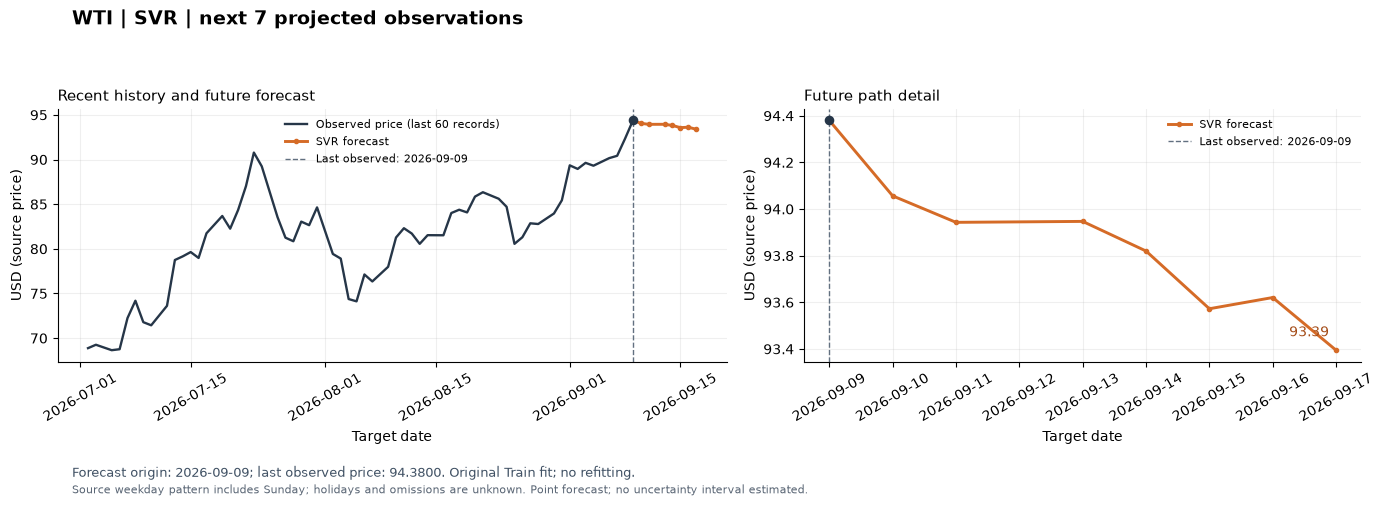

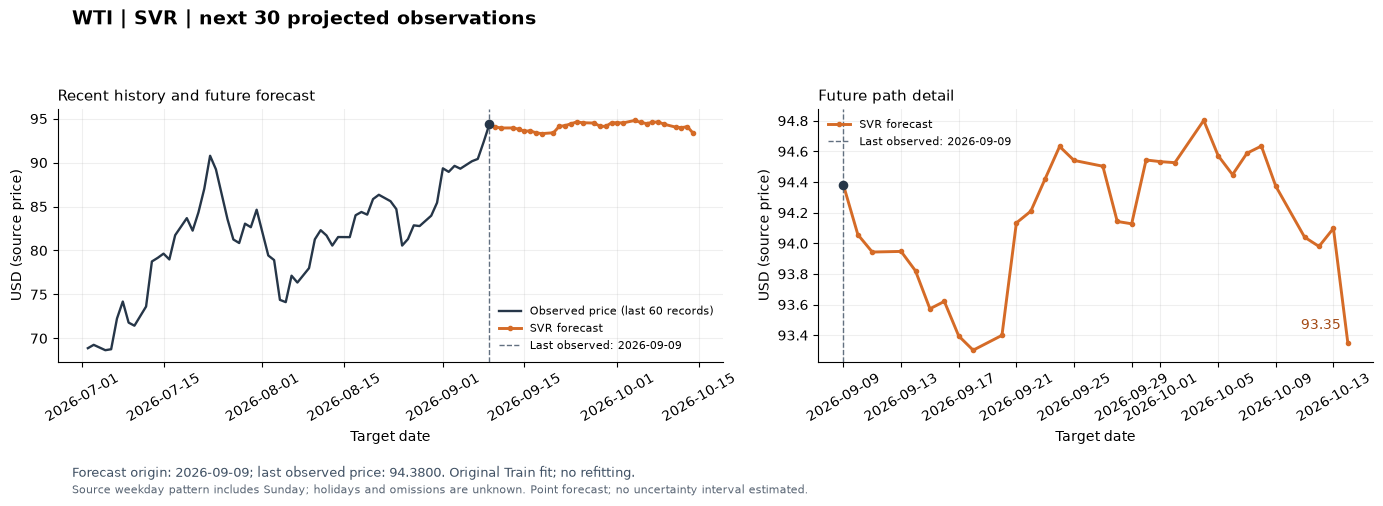

In [15]:
# Plot the already computed future path; no fitting or new inference.
FUTURE_MODEL_LABEL = 'SVR'
FUTURE_UNCERTAINTY_NOTE = 'Point forecast; no uncertainty interval estimated.'
FUTURE_PLOT_LABEL = 'WTI'
FUTURE_PLOT_UNIT = 'USD (source price)'
FUTURE_STEP_LABEL = 'projected observations'
FUTURE_DATE_NOTE = 'Source weekday pattern includes Sunday; holidays and omissions are unknown.'

def plot_model_future_path(history, future_path, steps):
    path = future_path.sort_values('h').iloc[:steps].copy()
    origin = pd.Timestamp(history.index[-1])
    last_actual = float(history.iloc[-1])
    forecast_column = next(c for c in ['svr_fc', 'xgb_fc', 'patchtst_fc_ens', 'forecast'] if c in path)
    seed_columns = [column for column in path if column.startswith(('patchtst_fc_seed', 'forecast_seed'))]
    dates = pd.DatetimeIndex(pd.to_datetime(path['target_date']))
    values = path[forecast_column].to_numpy(dtype=float)
    assert len(path) == steps and path['h'].tolist() == list(range(1, steps + 1))
    assert dates.is_unique and dates.is_monotonic_increasing and (dates > origin).all()
    assert (pd.to_datetime(path['origin_date']) == origin).all()
    assert np.isfinite(values).all() and (values > 0).all()
    np.testing.assert_allclose(path['price_origin'], last_actual, rtol=1e-12)

    joined_dates = pd.DatetimeIndex([origin, *dates])
    joined_forecast = np.r_[last_actual, values]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.2, 1]})
    recent = history.iloc[-60:]
    axes[0].plot(recent.index, recent, color='#263648', linewidth=1.7, label='Observed price (last 60 records)')
    for ax in axes:
        ax.plot(joined_dates, joined_forecast, color='#d56b27', linewidth=2.1,
                marker='o', markersize=3, label=f'{FUTURE_MODEL_LABEL} forecast')
        ax.axvline(origin, color='#627080', linestyle='--', linewidth=1,
                   label=f'Last observed: {origin:%Y-%m-%d}')
        ax.scatter([origin], [last_actual], color='#263648', s=35, zorder=4)
        if seed_columns:
            seed_values = path[seed_columns].to_numpy(dtype=float)
            assert np.isfinite(seed_values).all() and (seed_values > 0).all()
            low = np.r_[last_actual, seed_values.min(axis=1)]
            high = np.r_[last_actual, seed_values.max(axis=1)]
            ax.fill_between(joined_dates, low, high, color='#d56b27', alpha=.13,
                            label=f'Range across {len(seed_columns)} seeds')
        if {'xgb_lo95', 'xgb_hi95'}.issubset(path.columns):
            interval = path[['xgb_lo95', 'xgb_hi95']].to_numpy(dtype=float)
            assert np.isfinite(interval).all() and (interval > 0).all()
            assert (interval[:, 0] <= interval[:, 1]).all()
            ax.fill_between(joined_dates, np.r_[last_actual, interval[:, 0]],
                            np.r_[last_actual, interval[:, 1]], color='#d56b27', alpha=.13,
                            label='Nominal 95% quantile prediction interval')
        ax.set(ylabel=FUTURE_PLOT_UNIT, xlabel='Target date')
        ax.grid(alpha=.2)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(axis='x', labelrotation=30)
    axes[0].set_title('Recent history and future forecast', loc='left', fontsize=11)
    axes[1].set_title('Future path detail', loc='left', fontsize=11)
    endpoint_label = f'{values[-1]:,.6f}' if FUTURE_PLOT_LABEL == 'USD/EUR' else f'{values[-1]:,.2f}'
    axes[1].annotate(endpoint_label, xy=(dates[-1], values[-1]),
                     xytext=(-5, 10), textcoords='offset points', ha='right', color='#a34a15')
    axes[0].legend(loc='best', fontsize=8, frameon=False)
    axes[1].legend(loc='best', fontsize=8, frameon=False)
    fig.suptitle(f'{FUTURE_PLOT_LABEL} | {FUTURE_MODEL_LABEL} | next {steps} {FUTURE_STEP_LABEL}',
                 fontsize=14, fontweight='bold', x=.055, ha='left')
    fig.text(.055, .045, f'Forecast origin: {origin:%Y-%m-%d}; last observed price: {last_actual:,.4f}. '
             'Original Train fit; no refitting.', fontsize=9, color='#405164')
    fig.text(.055, .012, FUTURE_DATE_NOTE + ' ' + FUTURE_UNCERTAINTY_NOTE,
             fontsize=8, color='#596574')
    fig.tight_layout(rect=(0, .08, 1, .92))
    return fig

for future_steps in [7, 30]:
    future_fig = plot_model_future_path(df['Price'], future_forecast_daily, future_steps)
    plt.show()
    plt.close(future_fig)

<a id="task1-future-metrics"></a>

### 11.3 — Task 1: Original archived future forecast RMSE/MAPE

**Source:** original saved forecasts from **9 September 2026**, evaluated against `WTI_USD Historical Data (2).csv` in `ACTUAL_FOR_PREDICT`. Match by the original target dates; no retraining, calendar changes, date shifting or price imputation. These future forecasts have now been observed; this evaluation is separate from the historical Test set.

The tables show (A) actual/forecast pairs, (B) requested horizons, and (C) whole 7/30-step paths. **One origin gives n=1 per horizon**, so per-horizon RMSE is absolute error and MAPE is the single percentage error. Path metrics combine different horizons from that origin; they are not rolling-origin Test scores. Missing dates stay N/A and partial-window counts are explicit.

**Units:** RMSE in USD (source price); MAPE in percent. **Forecast precision:** full precision saved forecast CSV; checked against saved notebook output. LSTM/Transformer use the original predefined-seed ensemble forecast, not an average of seed metrics. Archive values are embedded in the next cell and cannot be overwritten by later inference.

[Go to Task 2 — Test set](#task2-test-metrics)


In [16]:
# Evaluate an immutable archive of the original forecasts, without fitting any model.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, HTML

task1_model = 'SVR'
task1_asset = 'WTI'
task1_unit = 'USD (source price)'
task1_horizons = [1, 3, 5, 7, 14, 21, 30]
task1_archive_provenance = {'source': 'OUTPUT\\SVR_WTI\\tables\\future_forecast_daily_30d.csv', 'precision': 'full precision saved forecast CSV; checked against saved notebook output', 'original_notebook_sha256': '5b746b6800a3610dbb9c07abe8ee166be4acbabb86b3d4ff747ef8580ec4cbc1', 'original_data_source': 'CSV/WTI_USD Historical Data.csv', 'original_data_sha256': 'ff2559efca294aa13a62319513cc142caffd4d65da39ea75f02432efa4cd3aad'}
task1_archive = pd.DataFrame(json.loads('[{"origin_date": "2026-09-09", "h": 1, "target_date": "2026-09-10", "Forecast": 94.05026083215712}, {"origin_date": "2026-09-09", "h": 2, "target_date": "2026-09-11", "Forecast": 93.30643920744455}, {"origin_date": "2026-09-09", "h": 3, "target_date": "2026-09-13", "Forecast": 93.79539825604778}, {"origin_date": "2026-09-09", "h": 4, "target_date": "2026-09-14", "Forecast": 93.41074514991804}, {"origin_date": "2026-09-09", "h": 5, "target_date": "2026-09-15", "Forecast": 94.216984640573}, {"origin_date": "2026-09-09", "h": 6, "target_date": "2026-09-16", "Forecast": 93.9965092411316}, {"origin_date": "2026-09-09", "h": 7, "target_date": "2026-09-17", "Forecast": 93.71523383373378}, {"origin_date": "2026-09-09", "h": 8, "target_date": "2026-09-18", "Forecast": 93.89446476808844}, {"origin_date": "2026-09-09", "h": 9, "target_date": "2026-09-20", "Forecast": 92.8002182164692}, {"origin_date": "2026-09-09", "h": 10, "target_date": "2026-09-21", "Forecast": 94.17868695798236}, {"origin_date": "2026-09-09", "h": 11, "target_date": "2026-09-22", "Forecast": 94.2224842042018}, {"origin_date": "2026-09-09", "h": 12, "target_date": "2026-09-23", "Forecast": 95.10247879022282}, {"origin_date": "2026-09-09", "h": 13, "target_date": "2026-09-24", "Forecast": 95.07901407352642}, {"origin_date": "2026-09-09", "h": 14, "target_date": "2026-09-25", "Forecast": 94.9843128119646}, {"origin_date": "2026-09-09", "h": 15, "target_date": "2026-09-27", "Forecast": 95.50615446494412}, {"origin_date": "2026-09-09", "h": 16, "target_date": "2026-09-28", "Forecast": 94.74181900885274}, {"origin_date": "2026-09-09", "h": 17, "target_date": "2026-09-29", "Forecast": 94.5951371730952}, {"origin_date": "2026-09-09", "h": 18, "target_date": "2026-09-30", "Forecast": 95.77857953706716}, {"origin_date": "2026-09-09", "h": 19, "target_date": "2026-10-01", "Forecast": 96.98033975839806}, {"origin_date": "2026-09-09", "h": 20, "target_date": "2026-10-02", "Forecast": 96.44753147387549}, {"origin_date": "2026-09-09", "h": 21, "target_date": "2026-10-04", "Forecast": 97.50982216834406}, {"origin_date": "2026-09-09", "h": 22, "target_date": "2026-10-05", "Forecast": 96.87983633697192}, {"origin_date": "2026-09-09", "h": 23, "target_date": "2026-10-06", "Forecast": 97.11707873924784}, {"origin_date": "2026-09-09", "h": 24, "target_date": "2026-10-07", "Forecast": 97.5852277367704}, {"origin_date": "2026-09-09", "h": 25, "target_date": "2026-10-08", "Forecast": 97.4120461592752}, {"origin_date": "2026-09-09", "h": 26, "target_date": "2026-10-09", "Forecast": 96.84382738888768}, {"origin_date": "2026-09-09", "h": 27, "target_date": "2026-10-11", "Forecast": 96.06395893547464}, {"origin_date": "2026-09-09", "h": 28, "target_date": "2026-10-12", "Forecast": 96.17701905298838}, {"origin_date": "2026-09-09", "h": 29, "target_date": "2026-10-13", "Forecast": 95.50945631453466}, {"origin_date": "2026-09-09", "h": 30, "target_date": "2026-10-14", "Forecast": 93.163560539466}]'))
task1_root = next(base for base in [Path.cwd(), *Path.cwd().parents]
    if (base / 'ACTUAL_FOR_PREDICT').is_dir() and (base / 'CSV').is_dir())
task1_actual_path = task1_root / 'ACTUAL_FOR_PREDICT' / 'WTI_USD Historical Data (2).csv'
task1_actual = pd.read_csv(task1_actual_path, encoding='utf-8-sig')
task1_actual['target_date'] = pd.to_datetime(task1_actual['Date'], format='%m/%d/%Y', errors='raise')
task1_actual['Actual'] = pd.to_numeric(task1_actual['Price'].astype(str).str.replace(',', '', regex=False), errors='raise')
assert task1_actual['target_date'].notna().all() and not task1_actual['target_date'].duplicated().any()
assert np.isfinite(task1_actual['Actual']).all() and task1_actual['Actual'].gt(0).all()
for task1_column in ['origin_date', 'target_date']:
    task1_archive[task1_column] = pd.to_datetime(task1_archive[task1_column], errors='raise')
assert task1_archive['h'].tolist() == list(range(1, 31))
assert task1_archive['origin_date'].nunique() == 1 and task1_archive['target_date'].is_unique
assert task1_archive['target_date'].is_monotonic_increasing
assert (task1_archive['target_date'] > task1_archive['origin_date']).all()
assert np.isfinite(task1_archive['Forecast']).all() and task1_archive['Forecast'].gt(0).all()

task1_comparison = task1_archive.merge(task1_actual[['target_date', 'Actual']],
    on='target_date', how='left', validate='one_to_one')
np.testing.assert_array_equal(task1_comparison['Forecast'], task1_archive['Forecast'])
assert len(task1_comparison) == 30
task1_comparison['Error'] = task1_comparison['Forecast'] - task1_comparison['Actual']
task1_comparison['APE (%)'] = 100 * task1_comparison['Error'].abs() / task1_comparison['Actual']
task1_comparison['Status'] = np.where(task1_comparison['Actual'].notna(),
    'Matched original target date', 'Missing actual: original target date retained')
task1_horizon_metrics = task1_comparison.loc[task1_comparison.h.isin(task1_horizons),
    ['origin_date', 'h', 'target_date', 'Forecast', 'Actual']].copy()
task1_horizon_metrics['n_actuals'] = task1_horizon_metrics['Actual'].notna().astype(int)
task1_horizon_metrics['RMSE'] = (task1_horizon_metrics['Forecast'] - task1_horizon_metrics['Actual']).abs()
task1_horizon_metrics['RMSE_unit'] = task1_unit
task1_horizon_metrics['MAPE (%)'] = 100 * task1_horizon_metrics['RMSE'] / task1_horizon_metrics['Actual']
task1_window_rows = []
for task1_window in [7, 30]:
    task1_part = task1_comparison.loc[task1_comparison.h.le(task1_window)]
    task1_matched = task1_part.dropna(subset=['Actual'])
    task1_error = task1_matched['Forecast'].to_numpy() - task1_matched['Actual'].to_numpy()
    task1_window_rows.append(dict(window_steps=task1_window, n_expected=len(task1_part),
        n_actuals=len(task1_matched), n_missing=len(task1_part)-len(task1_matched),
        first_target_date=task1_part.target_date.min(), last_target_date=task1_part.target_date.max(),
        RMSE=float(np.sqrt(np.mean(task1_error**2))) if len(task1_matched) else np.nan,
        RMSE_unit=task1_unit,
        MAPE_percent=float(100*np.mean(np.abs(task1_error/task1_matched['Actual'].to_numpy()))) if len(task1_matched) else np.nan,
        Status='Complete' if len(task1_part)==len(task1_matched) else 'Partial: matched dates only'))
task1_window_metrics = pd.DataFrame(task1_window_rows).rename(columns={'MAPE_percent': 'MAPE (%)'})
task1_missing = task1_comparison.loc[task1_comparison.Actual.isna(), ['h', 'target_date']].copy()

def task1_show_table(frame):
    shown = frame.copy()
    for column in ['origin_date', 'target_date', 'first_target_date', 'last_target_date']:
        if column in shown:
            shown[column] = pd.to_datetime(shown[column]).dt.strftime('%Y-%m-%d')
    display(HTML('<div style="max-height:420px;overflow:auto;border:1px solid #ddd;padding:8px">'
        + shown.to_html(index=False, na_rep='N/A', float_format=lambda value: f'{value:,.6f}') + '</div>'))

display(Markdown('**Task 1A — Original future forecast / actual pairs (prices in ' + task1_unit + ')**'))
task1_show_table(task1_comparison)
display(Markdown('**Task 1B — Future RMSE/MAPE by horizon; one original origin, n=1 per horizon**'))
task1_show_table(task1_horizon_metrics)
display(Markdown('**Task 1C — RMSE/MAPE across each plotted 7/30-step future path (mixed horizons)**'))
task1_show_table(task1_window_metrics)
if not task1_missing.empty:
    display(Markdown('**Missing actual prices: no date shifting or imputation**'))
    task1_show_table(task1_missing)
task1_output = task1_root / 'OUTPUT' / 'METRICS_REVIEW' / 'Task1_Future' / 'SVR_WTI'
task1_output.mkdir(parents=True, exist_ok=True)
for task1_name, task1_frame in [('original_forecast_archive.csv', task1_archive),
        ('forecast_actual_pairs.csv', task1_comparison), ('metrics_by_horizon.csv', task1_horizon_metrics),
        ('metrics_7_30_steps.csv', task1_window_metrics), ('missing_actual_dates.csv', task1_missing)]:
    task1_frame.to_csv(task1_output / task1_name, index=False, encoding='utf-8-sig')
task1_provenance = dict(task1_archive_provenance, actual_source=str(task1_actual_path.relative_to(task1_root)),
    actual_sha256=hashlib.sha256(task1_actual_path.read_bytes()).hexdigest(),
    model=task1_model, asset=task1_asset, origin=str(task1_archive.origin_date.iloc[0].date()),
    forecast_sha256=hashlib.sha256(task1_archive.to_csv(index=False).encode('utf-8')).hexdigest(),
    matching='exact original target date; no imputation or date shifts', refit_for_evaluation=False)
(task1_output / 'provenance.json').write_text(json.dumps(task1_provenance, indent=2, ensure_ascii=False), encoding='utf-8')
print('Forecast source:', task1_archive_provenance['source'])
print('Actual prices:', task1_actual_path.name, '| forecast origin:', task1_archive.origin_date.iloc[0].date())
print('Per-horizon n=1: RMSE equals absolute error; MAPE is the single absolute percentage error.')
print('Window metrics mix horizons from one origin and are separate from Test-set performance.')
print('CSV results:', task1_output)

**Task 1A — Original future forecast / actual pairs (prices in USD (source price))**

origin_date,h,target_date,Forecast,Actual,Error,APE (%),Status
2026-09-09,1,2026-09-10,94.050261,100.620000,-6.569739,6.529258,Matched original target date
2026-09-09,2,2026-09-11,93.306439,96.620000,-3.313561,3.429477,Matched original target date
2026-09-09,3,2026-09-13,93.795398,98.770000,-4.974602,5.036551,Matched original target date
2026-09-09,4,2026-09-14,93.410745,98.100000,-4.689255,4.780076,Matched original target date
2026-09-09,5,2026-09-15,94.216985,100.630000,-6.413015,6.372866,Matched original target date
2026-09-09,6,2026-09-16,93.996509,97.050000,-3.053491,3.146307,Matched original target date
2026-09-09,7,2026-09-17,93.715234,96.300000,-2.584766,2.684077,Matched original target date
2026-09-09,8,2026-09-18,93.894465,95.260000,-1.365535,1.433482,Matched original target date
2026-09-09,9,2026-09-20,92.800218,95.280000,-2.479782,2.602626,Matched original target date
2026-09-09,10,2026-09-21,94.178687,91.800000,2.378687,2.591162,Matched original target date


**Task 1B — Future RMSE/MAPE by horizon; one original origin, n=1 per horizon**

origin_date,h,target_date,Forecast,Actual,n_actuals,RMSE,RMSE_unit,MAPE (%)
2026-09-09,1,2026-09-10,94.050261,100.620000,1,6.569739,USD (source price),6.529258
2026-09-09,3,2026-09-13,93.795398,98.770000,1,4.974602,USD (source price),5.036551
2026-09-09,5,2026-09-15,94.216985,100.630000,1,6.413015,USD (source price),6.372866
2026-09-09,7,2026-09-17,93.715234,96.300000,1,2.584766,USD (source price),2.684077
2026-09-09,14,2026-09-25,94.984313,91.390000,1,3.594313,USD (source price),3.932939
2026-09-09,21,2026-10-04,97.509822,89.870000,1,7.639822,USD (source price),8.500970
2026-09-09,30,2026-10-14,93.163561,93.620000,1,0.456439,USD (source price),0.487545


**Task 1C — RMSE/MAPE across each plotted 7/30-step future path (mixed horizons)**

window_steps,n_expected,n_actuals,n_missing,first_target_date,last_target_date,RMSE,RMSE_unit,MAPE (%),Status
7,7,7,0,2026-09-10,2026-09-17,4.751068,USD (source price),4.568373,Complete
30,30,28,2,2026-09-10,2026-10-14,5.228534,USD (source price),5.102531,Partial: matched dates only


**Missing actual prices: no date shifting or imputation**

h,target_date
27,2026-10-11
28,2026-10-12


Forecast source: OUTPUT\SVR_WTI\tables\future_forecast_daily_30d.csv
Actual prices: WTI_USD Historical Data (2).csv | forecast origin: 2026-09-09
Per-horizon n=1: RMSE equals absolute error; MAPE is the single absolute percentage error.
Window metrics mix horizons from one origin and are separate from Test-set performance.
CSV results: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\METRICS_REVIEW\Task1_Future\SVR_WTI


<a id="svr-revised-future"></a>

### 11.4 — Revised future RMSE/MAPE after Train-only Top 5 search

Evaluate the **new rank-1 Train-selected models** from this run against the supplied actual prices. Original archived-forecast metrics remain in the preceding section. This is retrospective evaluation on dates already inspected, not forecasts issued before those actual prices were known. Candidate ranking and model fitting exclude Test and these future actual prices. Missing original target dates remain N/A.


In [17]:
# Evaluate an immutable archive of the original forecasts, without fitting any model.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, HTML

svr_revised_model = 'SVR'
svr_revised_asset = 'WTI'
svr_revised_unit = 'USD (source price)'
svr_revised_horizons = [1, 3, 5, 7, 14, 21, 30]
svr_revised_archive_provenance = dict(source='Current Train-ranked SVR execution; full precision', precision='full precision; retrospective rerun after actual dates were inspected')
svr_revised_archive = future_forecast_daily[['origin_date', 'h', 'target_date', 'forecast']].copy().rename(columns={'forecast': 'Forecast'})
svr_revised_root = next(base for base in [Path.cwd(), *Path.cwd().parents]
    if (base / 'ACTUAL_FOR_PREDICT').is_dir() and (base / 'CSV').is_dir())
svr_revised_actual_path = svr_revised_root / 'ACTUAL_FOR_PREDICT' / 'WTI_USD Historical Data (2).csv'
svr_revised_actual = pd.read_csv(svr_revised_actual_path, encoding='utf-8-sig')
svr_revised_actual['target_date'] = pd.to_datetime(svr_revised_actual['Date'], format='%m/%d/%Y', errors='raise')
svr_revised_actual['Actual'] = pd.to_numeric(svr_revised_actual['Price'].astype(str).str.replace(',', '', regex=False), errors='raise')
assert svr_revised_actual['target_date'].notna().all() and not svr_revised_actual['target_date'].duplicated().any()
assert np.isfinite(svr_revised_actual['Actual']).all() and svr_revised_actual['Actual'].gt(0).all()
for svr_revised_column in ['origin_date', 'target_date']:
    svr_revised_archive[svr_revised_column] = pd.to_datetime(svr_revised_archive[svr_revised_column], errors='raise')
assert svr_revised_archive['h'].tolist() == list(range(1, 31))
assert svr_revised_archive['origin_date'].nunique() == 1 and svr_revised_archive['target_date'].is_unique
assert svr_revised_archive['target_date'].is_monotonic_increasing
assert (svr_revised_archive['target_date'] > svr_revised_archive['origin_date']).all()
assert np.isfinite(svr_revised_archive['Forecast']).all() and svr_revised_archive['Forecast'].gt(0).all()

svr_revised_comparison = svr_revised_archive.merge(svr_revised_actual[['target_date', 'Actual']],
    on='target_date', how='left', validate='one_to_one')
np.testing.assert_array_equal(svr_revised_comparison['Forecast'], svr_revised_archive['Forecast'])
assert len(svr_revised_comparison) == 30
svr_revised_comparison['Error'] = svr_revised_comparison['Forecast'] - svr_revised_comparison['Actual']
svr_revised_comparison['APE (%)'] = 100 * svr_revised_comparison['Error'].abs() / svr_revised_comparison['Actual']
svr_revised_comparison['Status'] = np.where(svr_revised_comparison['Actual'].notna(),
    'Matched original target date', 'Missing actual: original target date retained')
svr_revised_horizon_metrics = svr_revised_comparison.loc[svr_revised_comparison.h.isin(svr_revised_horizons),
    ['origin_date', 'h', 'target_date', 'Forecast', 'Actual']].copy()
svr_revised_horizon_metrics['n_actuals'] = svr_revised_horizon_metrics['Actual'].notna().astype(int)
svr_revised_horizon_metrics['RMSE'] = (svr_revised_horizon_metrics['Forecast'] - svr_revised_horizon_metrics['Actual']).abs()
svr_revised_horizon_metrics['RMSE_unit'] = svr_revised_unit
svr_revised_horizon_metrics['MAPE (%)'] = 100 * svr_revised_horizon_metrics['RMSE'] / svr_revised_horizon_metrics['Actual']
svr_revised_window_rows = []
for svr_revised_window in [7, 30]:
    svr_revised_part = svr_revised_comparison.loc[svr_revised_comparison.h.le(svr_revised_window)]
    svr_revised_matched = svr_revised_part.dropna(subset=['Actual'])
    svr_revised_error = svr_revised_matched['Forecast'].to_numpy() - svr_revised_matched['Actual'].to_numpy()
    svr_revised_window_rows.append(dict(window_steps=svr_revised_window, n_expected=len(svr_revised_part),
        n_actuals=len(svr_revised_matched), n_missing=len(svr_revised_part)-len(svr_revised_matched),
        first_target_date=svr_revised_part.target_date.min(), last_target_date=svr_revised_part.target_date.max(),
        RMSE=float(np.sqrt(np.mean(svr_revised_error**2))) if len(svr_revised_matched) else np.nan,
        RMSE_unit=svr_revised_unit,
        MAPE_percent=float(100*np.mean(np.abs(svr_revised_error/svr_revised_matched['Actual'].to_numpy()))) if len(svr_revised_matched) else np.nan,
        Status='Complete' if len(svr_revised_part)==len(svr_revised_matched) else 'Partial: matched dates only'))
svr_revised_window_metrics = pd.DataFrame(svr_revised_window_rows).rename(columns={'MAPE_percent': 'MAPE (%)'})
svr_revised_missing = svr_revised_comparison.loc[svr_revised_comparison.Actual.isna(), ['h', 'target_date']].copy()

def svr_revised_show_table(frame):
    shown = frame.copy()
    for column in ['origin_date', 'target_date', 'first_target_date', 'last_target_date']:
        if column in shown:
            shown[column] = pd.to_datetime(shown[column]).dt.strftime('%Y-%m-%d')
    display(HTML('<div style="max-height:420px;overflow:auto;border:1px solid #ddd;padding:8px">'
        + shown.to_html(index=False, na_rep='N/A', float_format=lambda value: f'{value:,.6f}') + '</div>'))

display(Markdown('**Task 1A — Revised Train-ranked future forecast / actual pairs (prices in ' + svr_revised_unit + ')**'))
svr_revised_show_table(svr_revised_comparison)
display(Markdown('**Task 1B — Future RMSE/MAPE by horizon; one original origin, n=1 per horizon**'))
svr_revised_show_table(svr_revised_horizon_metrics)
display(Markdown('**Task 1C — RMSE/MAPE across each plotted 7/30-step future path (mixed horizons)**'))
svr_revised_show_table(svr_revised_window_metrics)
if not svr_revised_missing.empty:
    display(Markdown('**Missing actual prices: no date shifting or imputation**'))
    svr_revised_show_table(svr_revised_missing)
svr_revised_output = svr_revised_root / 'OUTPUT' / 'METRICS_REVIEW' / 'Task1_Future_Revised_TrainSearch' / 'SVR_WTI'
svr_revised_output.mkdir(parents=True, exist_ok=True)
for svr_revised_name, svr_revised_frame in [('revised_forecast_snapshot.csv', svr_revised_archive),
        ('forecast_actual_pairs.csv', svr_revised_comparison), ('metrics_by_horizon.csv', svr_revised_horizon_metrics),
        ('metrics_7_30_steps.csv', svr_revised_window_metrics), ('missing_actual_dates.csv', svr_revised_missing)]:
    svr_revised_frame.to_csv(svr_revised_output / svr_revised_name, index=False, encoding='utf-8-sig')
svr_revised_provenance = dict(svr_revised_archive_provenance, actual_source=str(svr_revised_actual_path.relative_to(svr_revised_root)),
    actual_sha256=hashlib.sha256(svr_revised_actual_path.read_bytes()).hexdigest(),
    model=svr_revised_model, asset=svr_revised_asset, origin=str(svr_revised_archive.origin_date.iloc[0].date()),
    forecast_sha256=hashlib.sha256(svr_revised_archive.to_csv(index=False).encode('utf-8')).hexdigest(),
    matching='exact original target date; no imputation or date shifts', refit_for_evaluation=False)
(svr_revised_output / 'provenance.json').write_text(json.dumps(svr_revised_provenance, indent=2, ensure_ascii=False), encoding='utf-8')
print('Forecast source:', svr_revised_archive_provenance['source'])
print('Actual prices:', svr_revised_actual_path.name, '| forecast origin:', svr_revised_archive.origin_date.iloc[0].date())
print('Per-horizon n=1: RMSE equals absolute error; MAPE is the single absolute percentage error.')
print('Window metrics mix horizons from one origin and are separate from Test-set performance.')
print('CSV results:', svr_revised_output)

print('RETROSPECTIVE RERUN: these actual-price dates were already inspected; parameters were selected using Train only.')


**Task 1A — Revised Train-ranked future forecast / actual pairs (prices in USD (source price))**

origin_date,h,target_date,Forecast,Actual,Error,APE (%),Status
2026-09-09,1,2026-09-10,94.056530,100.620000,-6.563470,6.523027,Matched original target date
2026-09-09,2,2026-09-11,93.942961,96.620000,-2.677039,2.770689,Matched original target date
2026-09-09,3,2026-09-13,93.947009,98.770000,-4.822991,4.883053,Matched original target date
2026-09-09,4,2026-09-14,93.819964,98.100000,-4.280036,4.362932,Matched original target date
2026-09-09,5,2026-09-15,93.572430,100.630000,-7.057570,7.013386,Matched original target date
2026-09-09,6,2026-09-16,93.620558,97.050000,-3.429442,3.533686,Matched original target date
2026-09-09,7,2026-09-17,93.394680,96.300000,-2.905320,3.016947,Matched original target date
2026-09-09,8,2026-09-18,93.302036,95.260000,-1.957964,2.055390,Matched original target date
2026-09-09,9,2026-09-20,93.399213,95.280000,-1.880787,1.973958,Matched original target date
2026-09-09,10,2026-09-21,94.133118,91.800000,2.333118,2.541523,Matched original target date


**Task 1B — Future RMSE/MAPE by horizon; one original origin, n=1 per horizon**

origin_date,h,target_date,Forecast,Actual,n_actuals,RMSE,RMSE_unit,MAPE (%)
2026-09-09,1,2026-09-10,94.056530,100.620000,1,6.563470,USD (source price),6.523027
2026-09-09,3,2026-09-13,93.947009,98.770000,1,4.822991,USD (source price),4.883053
2026-09-09,5,2026-09-15,93.572430,100.630000,1,7.057570,USD (source price),7.013386
2026-09-09,7,2026-09-17,93.394680,96.300000,1,2.905320,USD (source price),3.016947
2026-09-09,14,2026-09-25,94.541153,91.390000,1,3.151153,USD (source price),3.448028
2026-09-09,21,2026-10-04,94.802215,89.870000,1,4.932215,USD (source price),5.488167
2026-09-09,30,2026-10-14,93.349460,93.620000,1,0.270540,USD (source price),0.288977


**Task 1C — RMSE/MAPE across each plotted 7/30-step future path (mixed horizons)**

window_steps,n_expected,n_actuals,n_missing,first_target_date,last_target_date,RMSE,RMSE_unit,MAPE (%),Status
7,7,7,0,2026-09-10,2026-09-17,4.808280,USD (source price),4.586246,Complete
30,30,28,2,2026-09-10,2026-10-14,4.157667,USD (source price),4.045264,Partial: matched dates only


**Missing actual prices: no date shifting or imputation**

h,target_date
27,2026-10-11
28,2026-10-12


Forecast source: Current Train-ranked SVR execution; full precision
Actual prices: WTI_USD Historical Data (2).csv | forecast origin: 2026-09-09
Per-horizon n=1: RMSE equals absolute error; MAPE is the single absolute percentage error.
Window metrics mix horizons from one origin and are separate from Test-set performance.
CSV results: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\METRICS_REVIEW\Task1_Future_Revised_TrainSearch\SVR_WTI
RETROSPECTIVE RERUN: these actual-price dates were already inspected; parameters were selected using Train only.


## 12. Process checks and RMSE/MAPE
Check all alignment, counts, unique origins, finite outputs and valid inverse transforms before scoring. Export offending rows and stop on failure; do not clip. Report RMSE in original units, MAPE in percent and sample size separately by horizon. Zero actuals make group MAPE undefined rather than changing the denominator.

In [18]:
def validate_forecasts(frame,label):
    cols=[c for c in ['actual','forecast','price_origin','lower95','upper95'] if c in frame]
    good=np.isfinite(frame[cols]).all(axis=1) & frame.forecast.gt(0)
    if 'actual' in frame: good &= frame.actual.gt(0)
    if 'lower95' in frame: good &= frame.lower95.gt(0) & frame.lower95.le(frame.forecast) & frame.forecast.le(frame.upper95)
    save_table(frame.loc[~good],f'{label}_offending_rows.csv')
    check(f'{label}: finite and valid log inversion',bool(good.all()),'No clipping or post-Test parameter revision.')
    check(f'{label}: unique origin/horizon',not frame.duplicated(['origin_date','h']).any())
    if 'target_index' in frame:
        check(f'{label}: target alignment',bool((frame.target_index==frame.origin_index+frame.h).all()) and
            (frame.target_index>=n_train).all() and (frame.target_index<n).all() and
            np.array_equal(pd.to_datetime(frame.target_date).to_numpy(),df.index[frame.target_index].to_numpy()) and
            np.array_equal(pd.to_datetime(frame.origin_date).to_numpy(),df.index[frame.origin_index].to_numpy()) and
            np.array_equal(frame.actual.to_numpy(),prices[frame.target_index]),
            'Dates come from actual observed row positions, never calendar-day addition.')
        for h in HORIZONS:
            check(f'{label}: h={h} count',int(frame.h.eq(h).sum())==n_test-h+1,statistic=int(frame.h.eq(h).sum()))
    else:
        check(f'{label}: future-only dates',bool((frame.target_date>df.index[-1]).all()) and len(frame)==len(HORIZONS))
validate_forecasts(forecasts,'test')
validate_forecasts(future_forecasts,'future')
def score(frame):
    rows=[]
    for h,g in frame.groupby('h',sort=True):
        actual=g.actual.to_numpy(); forecast=g.forecast.to_numpy()
        zero=int((actual==0).sum())
        rows.append(dict(h=h,n=len(g),first_target_date=g.target_date.min(),last_target_date=g.target_date.max(),
            RMSE=np.sqrt(np.mean((actual-forecast)**2)),MAPE=np.nan if zero else 100*np.mean(np.abs((actual-forecast)/actual)),
            zero_actuals=zero,RMSE_unit=UNIT,MAPE_unit='%'))
    return pd.DataFrame(rows)
evaluation=score(forecasts)
save_table(evaluation,'metrics_by_horizon.csv')
display(Markdown('### Historical Test RMSE and MAPE (after forecast tables)'))
display(evaluation)
seed_metrics=None
if seed_forecasts:
    frames=[]
    for seed,frame in seed_forecasts.items():
        validate_forecasts(frame,f'seed{seed}_test')
        save_table(frame,f'seed{seed}_test_forecasts.csv')
        metrics=score(frame); metrics.insert(0,'seed',seed); frames.append(metrics)
    seed_metrics=pd.concat(frames,ignore_index=True)
    save_table(seed_metrics,'seed_metrics.csv')
    seed_summary=seed_metrics.groupby('h').agg(RMSE_mean=('RMSE','mean'),RMSE_SD=('RMSE','std'),MAPE_mean=('MAPE','mean'),MAPE_SD=('MAPE','std')).reset_index()
    save_table(seed_summary,'seed_metric_summary.csv')
    display(Markdown('Individual seeds and sample SD (ddof=1); separate from return-space ensemble metrics'))
    display(seed_metrics); display(seed_summary)

### Historical Test RMSE and MAPE (after forecast tables)

,h,n,first_target_date,last_target_date,RMSE,MAPE,zero_actuals,RMSE_unit,MAPE_unit
0,1,321,2025-08-28,2026-09-09,2.928988,2.168761,0,USD (source price),%
1,3,319,2025-08-31,2026-09-09,4.649472,3.829099,0,USD (source price),%
2,5,317,2025-09-02,2026-09-09,5.654981,4.835307,0,USD (source price),%
3,7,315,2025-09-04,2026-09-09,6.918063,5.729194,0,USD (source price),%
4,14,308,2025-09-12,2026-09-09,9.387462,7.727068,0,USD (source price),%
5,21,301,2025-09-21,2026-09-09,11.531864,9.672128,0,USD (source price),%
6,30,292,2025-10-01,2026-09-09,14.550241,12.280949,0,USD (source price),%


<a id="task2-test-metrics"></a>

### Task 2: Test set RMSE/MAPE — Train-ranked SVR rerun

Current execution: each horizon uses its rank-1 parameter set selected solely from Train RMSE. This table is recomputed from the current original chronological Test 20% forecasts, with dates/counts/actual prices checked. The supplied future actuals are excluded. The Test period was inspected in earlier experiments, so this is a retrospective rerun rather than a new independent holdout.

[Top 5 Train parameter sets](#svr-top5-train) · [Original archived future evaluation](#task1-future-metrics)


In [19]:
# Recompute Test-set metrics from the original historical Test forecasts only.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display, HTML

task2_primary_column = 'forecast'
task2_unit = 'USD (source price)'
task2_model = 'SVR'
task2_asset = 'WTI'
task2_kind = 'model point forecast'
task2_test_pairs = forecasts[['origin_date', 'h', 'target_date', 'actual', task2_primary_column]].copy()
task2_test_pairs = task2_test_pairs.rename(columns={task2_primary_column: 'Forecast'})
for task2_column in ['origin_date', 'target_date']:
    task2_test_pairs[task2_column] = pd.to_datetime(task2_test_pairs[task2_column], errors='raise')
assert n_train == int(0.8 * len(df))
assert task2_test_pairs['target_date'].between(df.index[n_train], df.index[-1]).all()
assert not task2_test_pairs.duplicated(['origin_date', 'h']).any()
assert np.isfinite(task2_test_pairs[['actual', 'Forecast']]).all().all()
task2_target_positions = df.index.get_indexer(task2_test_pairs.target_date)
task2_origin_positions = df.index.get_indexer(task2_test_pairs.origin_date)
assert (task2_origin_positions >= 0).all() and (task2_target_positions >= n_train).all()
assert np.array_equal(task2_target_positions-task2_origin_positions, task2_test_pairs.h.to_numpy())
np.testing.assert_allclose(task2_test_pairs.actual.to_numpy(), df['Price'].iloc[task2_target_positions].to_numpy(), atol=0, rtol=1e-12)
task2_rows = []
for task2_h, task2_group in task2_test_pairs.groupby('h', sort=True):
    assert len(task2_group) == len(df)-n_train-int(task2_h)+1
    task2_actual = task2_group.actual.to_numpy()
    task2_error = task2_group.Forecast.to_numpy()-task2_actual
    task2_zero_count = int((task2_actual == 0).sum())
    task2_rows.append(dict(partition='Test', h=int(task2_h), n_points=len(task2_group),
        first_target_date=task2_group.target_date.min(), last_target_date=task2_group.target_date.max(),
        RMSE=float(np.sqrt(np.mean(task2_error**2))), RMSE_unit=task2_unit,
        MAPE_percent=float(100*np.mean(np.abs(task2_error/task2_actual))) if not task2_zero_count else np.nan,
        zero_actuals=task2_zero_count, forecast_kind=task2_kind))
task2_test_metrics = pd.DataFrame(task2_rows).rename(columns={'MAPE_percent': 'MAPE (%)'})
assert task2_test_metrics.h.tolist() == sorted(HORIZONS)
task2_shown = task2_test_metrics.copy()
for task2_column in ['first_target_date', 'last_target_date']:
    task2_shown[task2_column] = task2_shown[task2_column].dt.strftime('%Y-%m-%d')
display(HTML('<div style="max-height:420px;overflow:auto;border:1px solid #ddd;padding:8px">'
    + task2_shown.to_html(index=False, na_rep='N/A', float_format=lambda value: f'{value:,.6f}') + '</div>'))
task2_root = next(base for base in [Path.cwd(), *Path.cwd().parents]
    if (base / 'ACTUAL_FOR_PREDICT').is_dir() and (base / 'CSV').is_dir())
task2_output = task2_root / 'OUTPUT' / 'METRICS_REVIEW' / 'Task2_Test' / 'SVR_WTI'
task2_output.mkdir(parents=True, exist_ok=True)
task2_test_metrics.to_csv(task2_output / 'metrics_by_horizon.csv', index=False, encoding='utf-8-sig')
task2_test_pairs.to_csv(task2_output / 'test_forecast_pairs.csv', index=False, encoding='utf-8-sig')
print('Partition: original chronological Test 20%; actuals from ACTUAL_FOR_PREDICT are excluded.')
print('Test source:', 'OUTPUT\\SVR_WTI\\tables\\test_forecasts_all.csv (full precision; matched saved notebook tables)')
print('Forecast kind:', task2_kind, '| Units:', task2_unit, '| MAPE: percent')
print('CSV results:', task2_output)

partition,h,n_points,first_target_date,last_target_date,RMSE,RMSE_unit,MAPE (%),zero_actuals,forecast_kind
Test,1,321,2025-08-28,2026-09-09,2.928988,USD (source price),2.168761,0,model point forecast
Test,3,319,2025-08-31,2026-09-09,4.649472,USD (source price),3.829099,0,model point forecast
Test,5,317,2025-09-02,2026-09-09,5.654981,USD (source price),4.835307,0,model point forecast
Test,7,315,2025-09-04,2026-09-09,6.918063,USD (source price),5.729194,0,model point forecast
Test,14,308,2025-09-12,2026-09-09,9.387462,USD (source price),7.727068,0,model point forecast
Test,21,301,2025-09-21,2026-09-09,11.531864,USD (source price),9.672128,0,model point forecast
Test,30,292,2025-10-01,2026-09-09,14.550241,USD (source price),12.280949,0,model point forecast


Partition: original chronological Test 20%; actuals from ACTUAL_FOR_PREDICT are excluded.
Test source: OUTPUT\SVR_WTI\tables\test_forecasts_all.csv (full precision; matched saved notebook tables)
Forecast kind: model point forecast | Units: USD (source price) | MAPE: percent
CSV results: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\METRICS_REVIEW\Task2_Test\SVR_WTI


## 13. Forecast plots and reporting-only Test residual diagnostics
Higher horizons can have overlapping errors and different target counts. Descriptive diagnostic p-values and Train/Test scale comparisons do not trigger model changes.

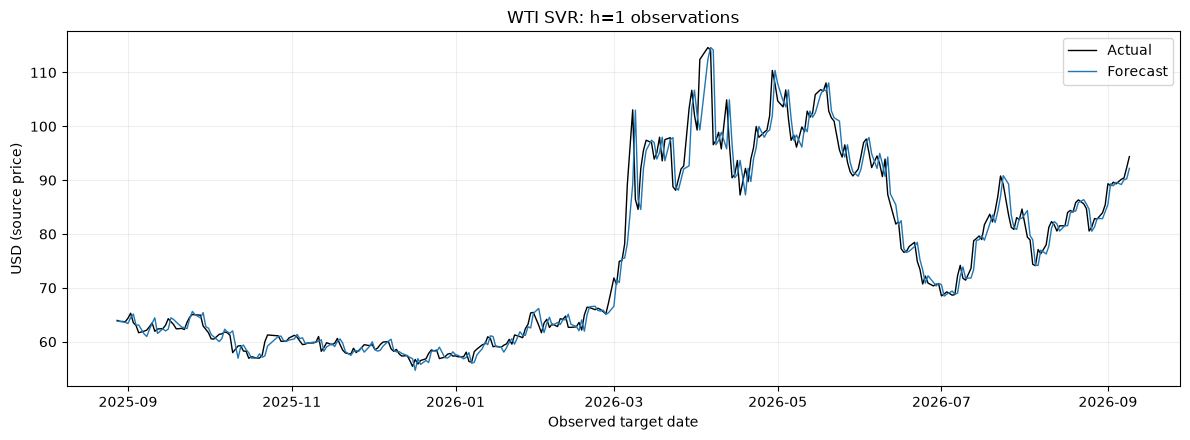

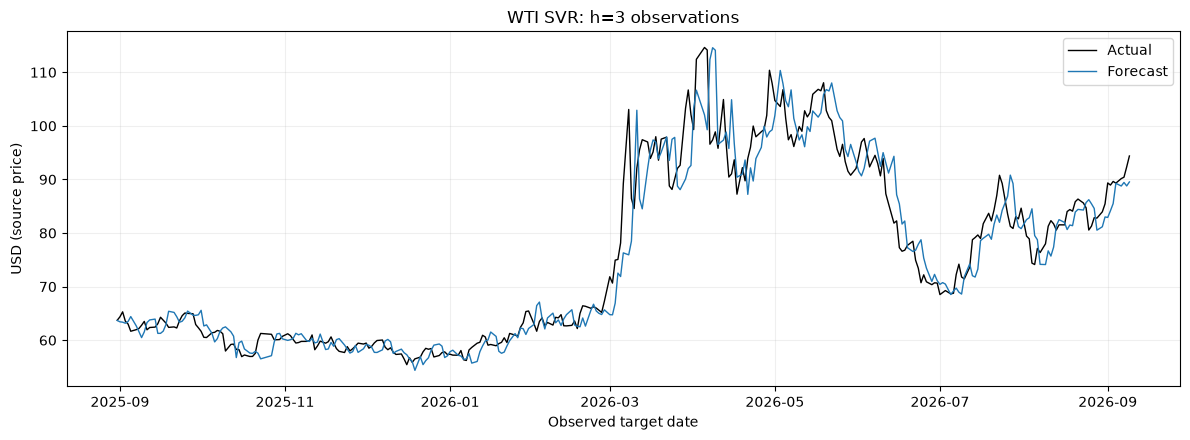

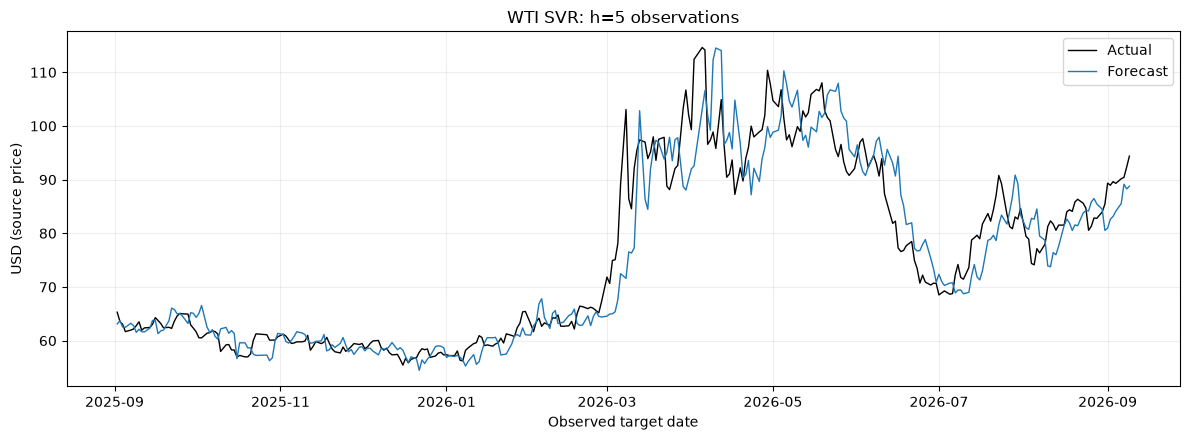

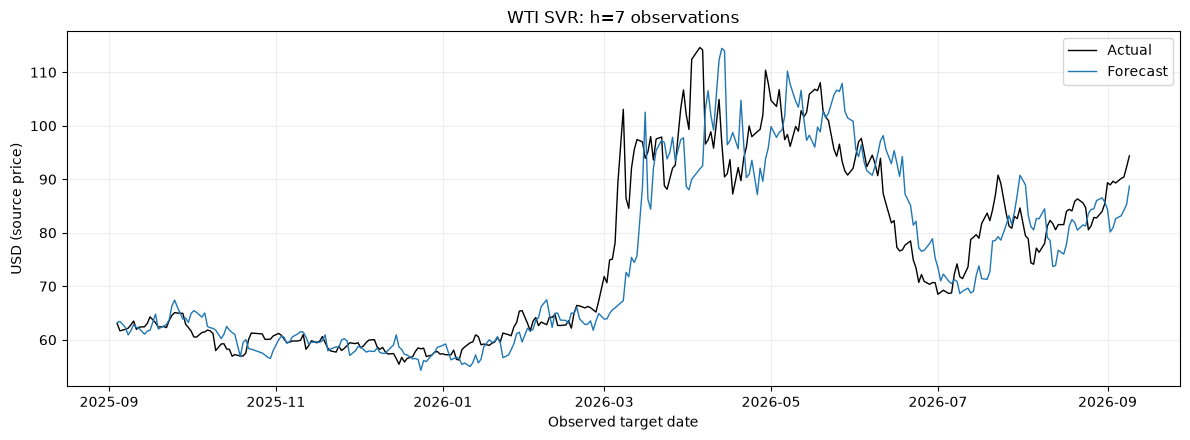

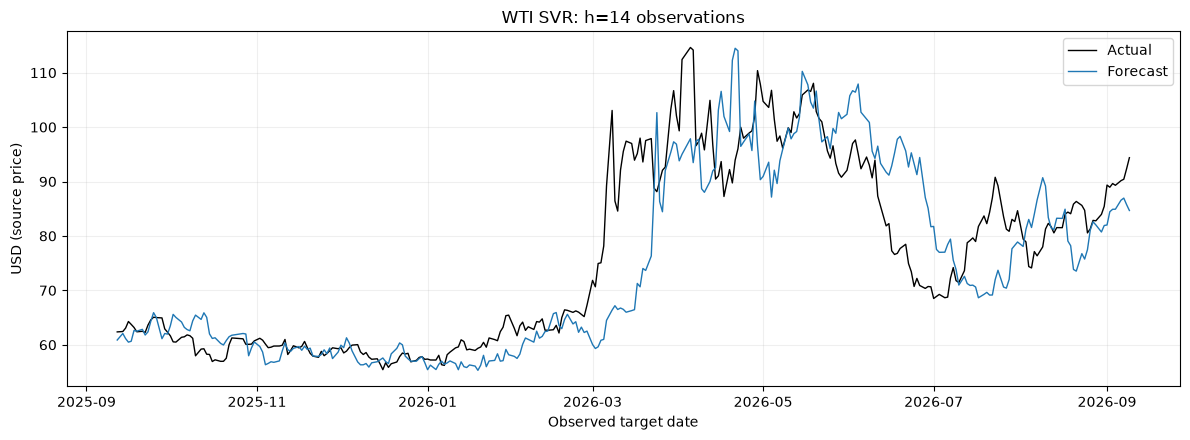

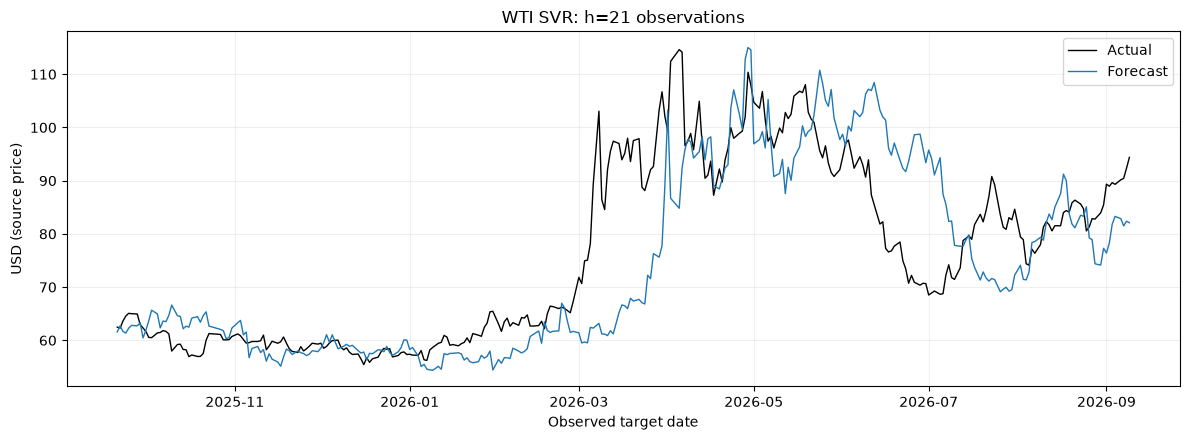

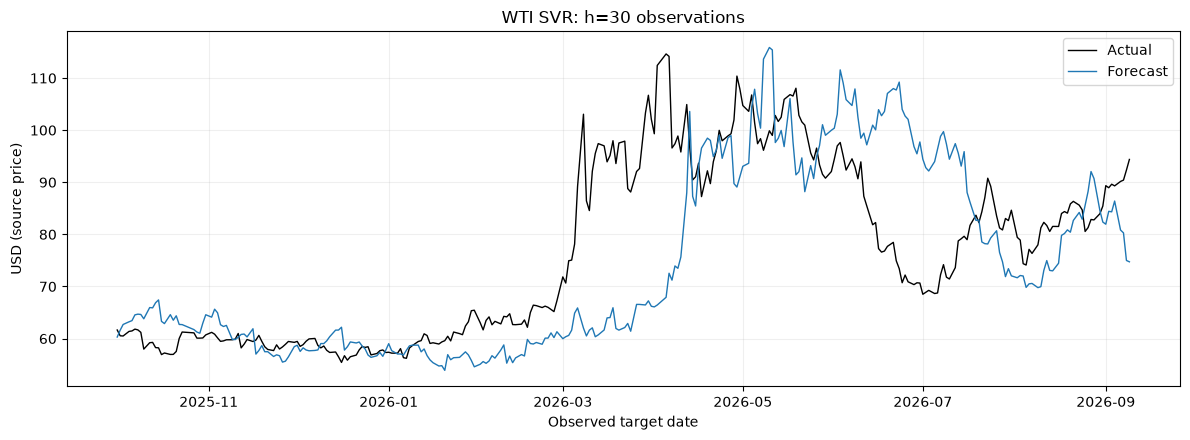

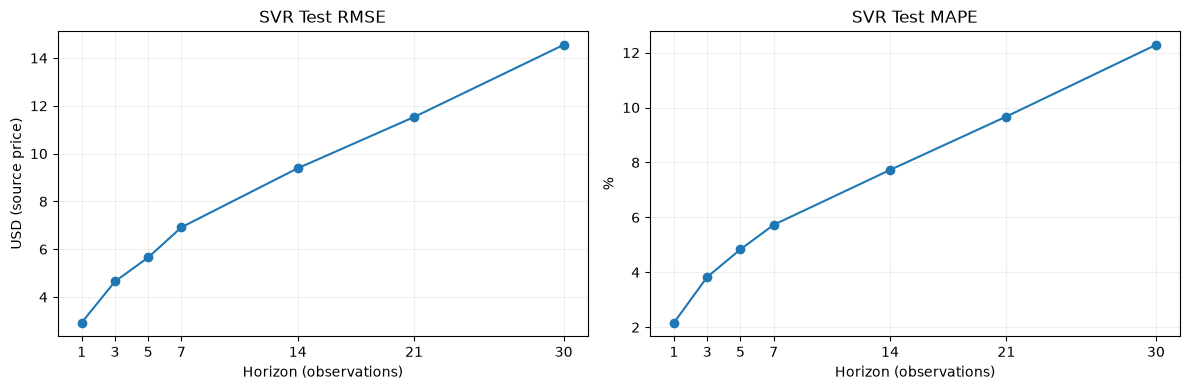

C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,sample,check,statistic,p_value,status,interpretation
0,Test cumulative log-return errors h=1; reporti...,Ljung-Box lag 10,24.993141,5.358522e-03,REPORTED,Evidence of serial correlation; model_df=0; re...
1,Test cumulative log-return errors h=1; reporti...,Ljung-Box lag 20,34.129834,2.525971e-02,REPORTED,Evidence of serial correlation; model_df=0; re...
2,Test cumulative log-return errors h=1; reporti...,Ljung-Box lag 30,49.482857,1.402685e-02,REPORTED,Evidence of serial correlation; model_df=0; re...
3,Test cumulative log-return errors h=1; reporti...,Residual mean t-test,0.648810,5.169265e-01,REPORTED,"Mean=0.0011882568; descriptive, dependent erro..."
4,Test cumulative log-return errors h=1; reporti...,ARCH LM,46.463081,1.182092e-06,REPORTED,Conditional variance evidence; no retuning
5,Test cumulative log-return errors h=1; reporti...,Jarque-Bera,591.121914,4.360210e-129,REPORTED,Normality diagnostic; skew=-0.32271; kurtosis=...


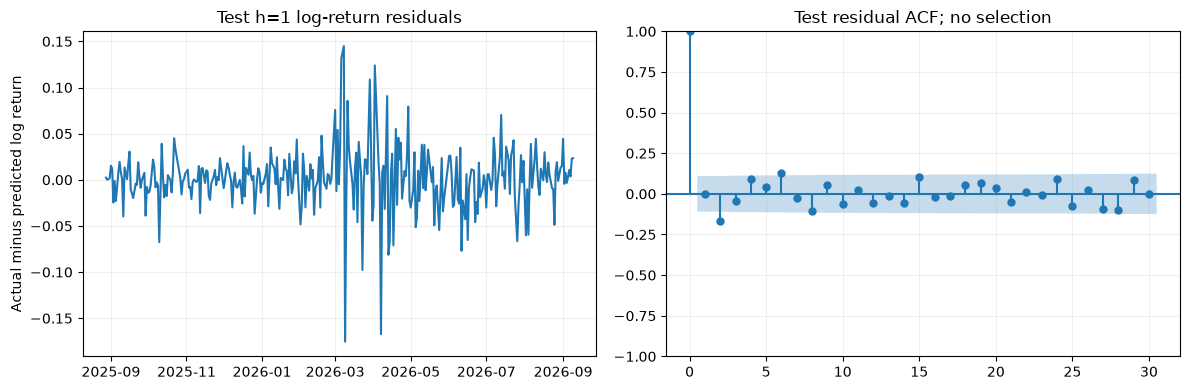

,sample,n,mean,SD,status
0,Train,1279,-0.000132,0.021209,REPORTED
1,Test,321,0.001230,0.032118,REPORTED


In [20]:
for h in HORIZONS:
    g=forecasts.loc[forecasts.h.eq(h)].sort_values('target_date')
    fig,ax=plt.subplots()
    ax.plot(g.target_date,g.actual,label='Actual',color='black',linewidth=1)
    ax.plot(g.target_date,g.forecast,label='Forecast',linewidth=1)
    if 'lower95' in g: ax.fill_between(g.target_date,g.lower95,g.upper95,alpha=.2,label='Model-based 95% interval')
    ax.set(title=f'{ASSET_NAME} {MODEL}: h={h} observations',xlabel='Observed target date',ylabel=UNIT)
    ax.legend(); save_figure(fig,f'test_forecast_h{h}.png')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric,unit in zip(axes,['RMSE','MAPE'],[UNIT,'%']):
    ax.plot(evaluation.h,evaluation[metric],marker='o')
    ax.set(title=f'{MODEL} Test {metric}',xlabel='Horizon (observations)',ylabel=unit,xticks=HORIZONS)
save_figure(fig,'metrics_by_horizon.png')
hdiag=HORIZONS[0]
g=forecasts.loc[forecasts.h.eq(hdiag)].sort_values('origin_date')
errors=np.log(g.actual/g.price_origin)-g.predicted_log_return
test_diagnostics=residual_report(errors,f'Test cumulative log-return errors h={hdiag}; reporting only')
save_table(test_diagnostics,'test_residual_diagnostics.csv'); display(test_diagnostics)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(g.target_date,errors); axes[0].set(title=f'Test h={hdiag} log-return residuals',ylabel='Actual minus predicted log return')
plot_acf(errors,lags=min(30,len(errors)//4),ax=axes[1]); axes[1].set_title('Test residual ACF; no selection')
save_figure(fig,'test_residual_diagnostics.png')
scale_comparison=pd.DataFrame([dict(sample='Train',n=n_train-1,mean=np.mean(returns[1:n_train]),SD=np.std(returns[1:n_train],ddof=1),status='REPORTED'),
    dict(sample='Test',n=n_test,mean=np.mean(returns[n_train:]),SD=np.std(returns[n_train:],ddof=1),status='REPORTED')])
save_table(scale_comparison,'return_scale_comparison.csv'); display(scale_comparison)

## 14. Summary generated from this execution
Rerunning regenerates this report from current results; there is no copied saved-result markdown.

In [21]:
lines=[f'# {ASSET_NAME} - {MODEL}: results from this execution','',
    f'Source: `{DATA_PATH.name}`; target: {TARGET_COL}; units: {UNIT}.',ASSET_NOTE,'',
    f'Raw chronological Train/Test: {n_train}/{n_test}; no validation.',
    f'Train: {df.index[0].date()} to {df.index[T].date()}; Test: {df.index[n_train].date()} to {df.index[-1].date()}.',
    f'Horizons: {HORIZONS} observations. Lookback: {LOOKBACK} observed returns for window models.',CALENDAR_NOTE,
    f'Source calendar audit: {len(missing_dates)} dates absent relative to the declared weekday pattern; maximum gap {int(gaps.calendar_days.max())} calendar days.',
    'Missing source dates are disclosed, not filled. Observation time therefore need not equal elapsed calendar time.',
    'Rolling origins begin at the final Train observation. Each forecast uses only history through its own origin; fitted parameters remain fixed.','',
    '## Model development']
if MODEL=='ARIMA':
    lines += [f'Selected {selected.model}; Train AIC={selected.AIC:.6f}; BIC={selected.BIC:.6f}.',
        'Differencing is the smallest Train ADF/KPSS-supported order. Selection uses AIC among converged fits with valid roots. Residual tests are reported without retuning.',
        'Exponentiated log forecasts are conditional medians, not bias-corrected arithmetic means. The 95% intervals are model-based; ARCH/non-normality and calendar irregularity limit interpretation.']
    if int(selected.p)==0 and d==1 and int(selected.q)==0 and selected.trend=='n':
        lines.append('ARIMA(0,1,0) without drift gives the latest observed price as the point forecast; uncertainty increases with horizon.')
elif MODEL=='SVR':
    lines += ['Direct RBF models use the rank-1 Train-price-RMSE candidate per horizon, around analytical C/epsilon/gamma references. No validation/cross-validation; all scalers fit Train only.']
elif MODEL=='XGBOOST':
    lines += ['Direct cumulative-log-return models use a fixed predeclared configuration. Learning curves are fitting data only. Raw gain is neither causal importance nor proof of future usefulness.']
else:
    lines += [f'MIMO predicts the next {MAX_H} individual observed-step log returns; prices compound the predicted path only.',
        f'All predefined seeds {SEEDS} are included equally; {EPOCHS} fixed epochs each. Average inverse-scaled returns before compounding.',
        'Ensemble metrics are not the mean seed metrics. Seed metric SD uses ddof=1 and is not a prediction interval.']
lines += ['', '## Historical Test metrics',markdown_table(evaluation),'',
    'Horizon groups have different counts and target dates; longer-horizon forecast errors overlap. These values do not establish a monotonic relationship with horizon.',
    'MAPE is an error percentage, not accuracy. Actual targets are checked for zeros; any zero would make the full-group MAPE undefined.',
    '', '## Future forecasts (no actuals or metrics)',markdown_table(future_forecasts),'',
    'Future dates are projections from a declared source-weekday pattern, not confirmed exchange sessions. Holidays or missing future records can shift them.',
    '', '## Checks and limitations',
    f'Process checks: {sum(row["status"]=="PASS" for row in process_rows)} passed; {sum(row["status"]=="FAIL" for row in process_rows)} failed.',
    'Train/Test diagnostics with no predeclared acceptance gate are REPORTED. Passing diagnostics does not establish forecast accuracy.',
    'No separate validation estimate or validation gap exists. Train fitting loss is optimistic; fixed budgets do not establish absence of overfitting.',
    'Test findings did not change parameters, epochs, transformations, seeds, or model selection.',
    'These univariate models do not observe news, monetary policy, interest rates, inflation, or unexpected market events.',
    f'All rows, figures, summaries and fitted artifacts are under OUTPUT/{MODEL}_{ASSET}/.',
    f'Tested Python executable: {sys.executable}.']
lines += ['', '**Daily future forecasts**', 'Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.']
summary='\n\n'.join(lines)
(SUMMARY_DIR/'execution_summary.md').write_text(summary,encoding='utf-8')
display(Markdown(summary))
write_json(SUMMARY_DIR/'execution_audit.json',dict(completed=True,asset=ASSET,model=MODEL,
    n=n,n_train=n_train,n_test=n_test,horizons=HORIZONS,counts={int(h):int(c) for h,c in forecasts.groupby('h').size().items()},
    train_end=str(df.index[T].date()),test_start=str(df.index[n_train].date()),last_observation=str(df.index[-1].date()),
    parameters_frozen=model_fingerprint()==frozen_state,process_checks=process_rows,
    source_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),seed_count=len(seed_forecasts),python_executable=sys.executable))
display(Markdown('**Current experiment:** Top 5 ranked by in-sample Train price RMSE; rank 1 selected per horizon. No validation/CV. Test/future periods were already inspected; this rerun is retrospective.'))


# WTI - SVR: results from this execution



Source: `WTI_USD Historical Data.csv`; target: Price; units: USD (source price).

The CSV identifies WTI/USD but does not identify instrument, contract, roll/adjustment treatment, close time, or timezone. Do not claim a specific futures contract or roll convention. Physical quotation is conventionally USD/barrel, but the file contains no unit metadata; metrics retain source USD price units.



Raw chronological Train/Test: 1280/321; no validation.

Train: 2021-07-01 to 2025-08-27; Test: 2025-08-28 to 2026-09-09.

Horizons: [1, 3, 5, 7, 14, 21, 30] observations. Lookback: 40 observed returns for window models.

Observation-index modeling; source dates retained without filling gaps. Future dates use the declared weekday pattern only; holidays, omitted records and source-session conventions remain unknown.

Source calendar audit: 25 dates absent relative to the declared weekday pattern; maximum gap 10 calendar days.

Missing source dates are disclosed, not filled. Observation time therefore need not equal elapsed calendar time.

Rolling origins begin at the final Train observation. Each forecast uses only history through its own origin; fitted parameters remain fixed.



## Model development

Direct RBF models use the rank-1 Train-price-RMSE candidate per horizon, around analytical C/epsilon/gamma references. No validation/cross-validation; all scalers fit Train only.



## Historical Test metrics

| h | n | first_target_date | last_target_date | RMSE | MAPE | zero_actuals | RMSE_unit | MAPE_unit |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 321 | 2025-08-28 00:00:00 | 2026-09-09 00:00:00 | 2.928988 | 2.168761 | 0 | USD (source price) | % |
| 3 | 319 | 2025-08-31 00:00:00 | 2026-09-09 00:00:00 | 4.649472 | 3.829099 | 0 | USD (source price) | % |
| 5 | 317 | 2025-09-02 00:00:00 | 2026-09-09 00:00:00 | 5.654981 | 4.835307 | 0 | USD (source price) | % |
| 7 | 315 | 2025-09-04 00:00:00 | 2026-09-09 00:00:00 | 6.918063 | 5.729194 | 0 | USD (source price) | % |
| 14 | 308 | 2025-09-12 00:00:00 | 2026-09-09 00:00:00 | 9.387462 | 7.727068 | 0 | USD (source price) | % |
| 21 | 301 | 2025-09-21 00:00:00 | 2026-09-09 00:00:00 | 11.531864 | 9.672128 | 0 | USD (source price) | % |
| 30 | 292 | 2025-10-01 00:00:00 | 2026-09-09 00:00:00 | 14.550241 | 12.280949 | 0 | USD (source price) | % |



Horizon groups have different counts and target dates; longer-horizon forecast errors overlap. These values do not establish a monotonic relationship with horizon.

MAPE is an error percentage, not accuracy. Actual targets are checked for zeros; any zero would make the full-group MAPE undefined.



## Future forecasts (no actuals or metrics)

| h | origin_date | target_date | target_date_status | price_origin | forecast |
| --- | --- | --- | --- | --- | --- |
| 1 | 2026-09-09 00:00:00 | 2026-09-10 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 94.380000 | 94.056530 |
| 3 | 2026-09-09 00:00:00 | 2026-09-13 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 94.380000 | 93.947009 |
| 5 | 2026-09-09 00:00:00 | 2026-09-15 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 94.380000 | 93.572430 |
| 7 | 2026-09-09 00:00:00 | 2026-09-17 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 94.380000 | 93.394680 |
| 14 | 2026-09-09 00:00:00 | 2026-09-25 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 94.380000 | 94.541153 |
| 21 | 2026-09-09 00:00:00 | 2026-10-04 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 94.380000 | 94.802215 |
| 30 | 2026-09-09 00:00:00 | 2026-10-14 00:00:00 | PROJECTED: weekday pattern, holidays/omissions unknown | 94.380000 | 93.349460 |



Future dates are projections from a declared source-weekday pattern, not confirmed exchange sessions. Holidays or missing future records can shift them.



## Checks and limitations

Process checks: 40 passed; 0 failed.

Train/Test diagnostics with no predeclared acceptance gate are REPORTED. Passing diagnostics does not establish forecast accuracy.

No separate validation estimate or validation gap exists. Train fitting loss is optimistic; fixed budgets do not establish absence of overfitting.

Test findings did not change parameters, epochs, transformations, seeds, or model selection.

These univariate models do not observe news, monetary policy, interest rates, inflation, or unexpected market events.

All rows, figures, summaries and fitted artifacts are under OUTPUT/SVR_WTI/.

Tested Python executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe.



**Daily future forecasts**

Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.

**Current experiment:** Top 5 ranked by in-sample Train price RMSE; rank 1 selected per horizon. No validation/CV. Test/future periods were already inspected; this rerun is retrospective.

## Implementation reference
- Local reference: `../BTC_TEST/SVR_BTC.ipynb` (read only; not rerun or modified).
- User protocol: `C:/Users/User/.codex/skills/time-series-forecasting/SKILL.md` and its asset-adaptation/model references.
- These notebooks adapt the local implementation; they do not claim replication of a separately tuned external study.